# 🔎 Here or There: *"Did I lose it here, or there?"*
**A last-seen object finder for one room, from a fixed phone camera (one photo every 30 s).**

Ask *"Where are my keys?"* and the notebook answers aloud, for example *"Your keys were on the armchair until 12:58 am. Not seen since."*

---
### Why this version is different from the first notebook
The first notebook cut every frame into 8 big zone crops and compared each crop with the registration photos using DINOv2. That cannot work well on this data:

| | size in a 3024 × 4032 frame |
|---|---|
| Keys | about **37 × 23 px** |
| Phone | about 55 × 27 px |
| A zone crop | about 1000 × 1000 px, shrunk to 224 px for DINOv2 |

After shrinking, the keys are a few pixels inside the crop, so the crop's embedding mostly describes the carpet or furniture, not the object.

**This notebook does this instead:**
1. Session 1 is already labelled in Roboflow (a box for every object in every frame). We **fine-tune a small YOLO detector** on those boxes. YOLO11-s has 9 M parameters, smaller than the 21 M of DINOv2 ViT-S/14, so it still suits a phone.
2. We cut every photo into **640 px tiles at full resolution**, so a 37-px key stays 37 px.
3. **Copy-paste augmentation** pastes object crops at random places and brightness levels. The detector then learns the objects and not their Session 1 positions, which change in Session 2.
4. Each object exists only once, so each frame keeps **only the best box per object**. A box's centre gives its **zone** (the 8-zone map from the proposal).
5. Last-seen logic runs on the history of frames up to the question time. It never looks at future frames.

### Protocol (kept from the proposal)
* **Session 1 (S1)** = training and calibration. The threshold τ comes from **2-fold cross-validation inside S1** (train on frames 1–10 and test on 11–20, then the reverse). It is **frozen** before Session 2 is touched.
* **Session 2 (S2)** = test set. The 50 test questions are drawn and saved **before** the detector sees any S2 photo.
* **Baselines:** random zone (1 in 8) and the *prior* (always answer the object's usual S1 zone).

### How to run
1. `Runtime → Change runtime type → T4 GPU` (free).
2. Check the folder names in **section 2**.
3. `Runtime → Run all`. A first run takes about 20–30 min, mostly training. Models and detections are cached in `My Drive/PauseFind_cache`, so later runs take a couple of minutes.

---
## 1. Setup
Installs [Ultralytics YOLO](https://docs.ultralytics.com) and gTTS (text-to-speech), then checks the GPU.

In [ ]:
import sys, subprocess, importlib.util

IN_COLAB = importlib.util.find_spec("google.colab") is not None

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

for module, package in [("ultralytics", "ultralytics"), ("gtts", "gTTS"),
                        ("pillow_heif", "pillow-heif"), ("openpyxl", "openpyxl")]:
    if importlib.util.find_spec(module) is None:
        print(f"installing {package} ...")
        _pip(package)

import os, re, io, json, glob, math, time, shutil, zipfile, hashlib, random, difflib, datetime as dt
from pathlib import Path
from collections import Counter, defaultdict
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw, ImageFont, ImageFilter
from IPython.display import display, Markdown, Audio, Javascript, HTML

try:
    import pillow_heif; pillow_heif.register_heif_opener()      # iPhone .HEIC photos
except Exception:
    pass

import torch
from ultralytics import YOLO

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SEED = 2026
random.seed(SEED); np.random.seed(SEED)

GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"
print(f"Environment : {'Google Colab' if IN_COLAB else 'local machine'}")
print(f"PyTorch     : {torch.__version__}")
print(f"Device      : {torch.cuda.get_device_name(0) if GPU else 'CPU only'}")
if not GPU:
    print("\n⚠️  No GPU. Training on CPU is very slow. In Colab: Runtime → Change runtime type → T4 GPU, then run again.")

Environment : Google Colab
PyTorch     : 2.14.1+cu130
Device      : Tesla T4


---
## 2. Connect Google Drive and find the data
The notebook looks for these folders anywhere in your Drive (names are matched loosely, so `Session1-pictures`, `session 1 pictures` and `Session1_pictures` all match):

| key | folder in your Drive | what it should contain |
|---|---|---|
| `s1` | `Session1-pictures` | the S1 photos **and** the Roboflow COCO export (`_annotations.coco.json`), zipped or unzipped |
| `s2` | `Session2-pictures` | the S2 photos, plus the Roboflow export if you labelled S2 |
| `registration` | `Registration Photos` | registration photos (optional, used for display, and for training if they have a Roboflow export) |
| `log` | `Placement_Log` | the placement log `.xlsx` (optional cross-check; the ground truth if S2 has no Roboflow labels) |

**If a folder is "Shared with me"** and not in *My Drive*: right-click it in Google Drive → *Organize → Add shortcut* → *My Drive*. Shortcuts are found too.
**If a name doesn't match**, edit `FOLDER_NAMES` below, or set `PROJECT_DIR` to the folder that contains them all.

In [ ]:
# ✏️ EDIT HERE if needed ------------------------------------------------------------
PROJECT_DIR = "P9"                 # folder inside My Drive that holds everything
FOLDER_NAMES = {
    "s1":           "Session1-pictures_-20261115T220605Z-1-001",
    "s2":           "Session2-pictures-20261116T213617Z-1-001",
    "registration": "Registration Photos",
    "log":          "Placement_Log",
}
LOG_PATTERNS = ["*placement*log*.xlsx", "*.xlsx"]
# -----------------------------------------------------------------------------------

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = "/content/drive/MyDrive"
    WORK = Path("/content/pf_work")                   # scratch space on the Colab disk
else:
    DRIVE_ROOT = os.environ.get("PF_DRIVE_ROOT", str(Path.cwd() / "drive"))
    WORK = Path(os.environ.get("PF_WORK", "/tmp/pf_work"))

CACHE = Path(DRIVE_ROOT) / "PauseFind_cache"
for p in [WORK, CACHE, CACHE / "models", CACHE / "detections"]:
    p.mkdir(parents=True, exist_ok=True)

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def _stem(p):
    return p.name[:-4] if p.name.lower().endswith(".zip") else p.name

PROJ = Path(DRIVE_ROOT) / PROJECT_DIR
if not PROJ.exists():
    print("Top of My Drive:", [k.name for k in sorted(Path(DRIVE_ROOT).iterdir())][:40])
    raise FileNotFoundError(f"'{PROJECT_DIR}' not found in My Drive. Fix PROJECT_DIR above.")
print("✓ project folder:", PROJ)

def _has_labels(p):
    """True if this folder/zip contains a Roboflow COCO export."""
    try:
        if p.is_file():
            with zipfile.ZipFile(p) as zf:
                return any(n.endswith(".json") and "coco" in n.lower() for n in zf.namelist())
        return any(True for _ in p.rglob("*coco*.json"))
    except Exception:
        return False

def find_item(name, max_depth=3):
    """All folders/zips in P9 whose name starts with `name`; prefer ones with Roboflow labels, then zips."""
    want, hits, frontier = _norm(name), [], [(PROJ, 0)]
    while frontier:
        d, depth = frontier.pop(0)
        try:
            kids = sorted(d.iterdir())
        except Exception:
            continue
        for k in kids:
            if (k.is_dir() or k.name.lower().endswith(".zip")) and _norm(_stem(k)).startswith(want):
                hits.append(k)
        if depth < max_depth:
            frontier += [(k, depth + 1) for k in kids if k.is_dir() and not k.name.startswith(".")]
    if not hits:
        return None, []
    ranked = sorted(hits, key=lambda k: (not _has_labels(k), not k.is_file(), len(k.parts)))
    return ranked[0], hits

def as_folder(p, key):
    """If the chosen item is a .zip, unzip it once to the Colab disk."""
    if p is None or p.is_dir():
        return p
    out = WORK / "unzipped" / key
    if not (out / ".done").exists():
        print(f"unzipping {p.name} ...")
        shutil.rmtree(out, ignore_errors=True); out.mkdir(parents=True)
        with zipfile.ZipFile(p) as zf:
            zf.extractall(out)
        (out / ".done").touch()
    return out

rows, FOUND = [], {}
for key, name in FOLDER_NAMES.items():
    best, hits = find_item(name)
    FOUND[key] = best
    rows.append({"key": key,
                 "chosen": str(best.relative_to(PROJ)) + (" (zip)" if best.is_file() else "") if best else "❌ not found",
                 "Roboflow labels?": ("yes" if _has_labels(best) else "no") if best else "",
                 "other copies": ", ".join(str(h.relative_to(PROJ)) for h in hits if h != best)})
display(pd.DataFrame(rows))
FOLDERS = {key: as_folder(p, key) for key, p in FOUND.items()}

if FOLDERS["s1"] is None:
    raise FileNotFoundError("Session 1 not found inside P9.")
if FOUND["s1"] and not _has_labels(FOUND["s1"]):
    print("⚠️ The chosen Session 1 copy has no Roboflow labels (_annotations.coco.json). Training needs them.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ project folder: /content/drive/MyDrive/P9


,key,chosen,Roboflow labels?,other copies
0,s1,Session1-pictures_-20261115T220605Z-1-001.zip ...,yes,
1,s2,Session2-pictures-20261116T213617Z-1-001.zip (...,yes,
2,registration,Code/registration_photos.zip (zip),no,Registration Photos
3,log,Placement_Log,no,


### 2.1 Copy the data to the Colab disk
Reading from Drive is slow, so each folder is copied once to `/content/pf_work`. Zip files, including zips inside zips, are unzipped.

In [ ]:
def describe(p):
    if p.is_file() and p.suffix.lower() == ".zip":
        with zipfile.ZipFile(p) as zf:
            names = zf.namelist()
    else:
        names = [str(f) for f in p.rglob("*")]
    imgs = sum(Path(n).suffix.lower() in IMG_EXT for n in names)
    jsons = sum(n.endswith(".json") for n in names)
    zips = sum(n.lower().endswith(".zip") for n in names)
    return imgs, jsons, zips

for k in sorted(Path("/content/drive/MyDrive/P9").iterdir()):
    if k.is_dir() or k.suffix.lower() == ".zip":
        try:
            i, j, z = describe(k)
            print(f"{k.name:55s} images={i:4d}  json={j}  zips inside={z}")
        except Exception as e:
            print(f"{k.name:55s} ⚠️ cannot read yet ({e})")

Code                                                    images=   0  json=0  zips inside=1
Notebook                                                images=  12  json=0  zips inside=0
Placement_Log                                           images=   0  json=0  zips inside=0
Registration Photos                                     images=  74  json=0  zips inside=3
Session1-Recordings                                     images=   1  json=0  zips inside=0
Session1-pictures                                       images=   5  json=0  zips inside=0
Session1-pictures_-20261115T220605Z-1-001.zip           images=  20  json=1  zips inside=0
Session2-pictures                                       images=  23  json=0  zips inside=0
Session2-pictures-20261116T213617Z-1-001.zip            images=  60  json=1  zips inside=0
Sessions                                                images=   0  json=0  zips inside=0


In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".heic", ".heif", ".webp", ".bmp"}
KEEP_EXT = IMG_EXT | {".json", ".xlsx", ".xls", ".csv", ".txt"}

# ✏️ the exact files/folders to use (inside My Drive/P9) ------------------------------
P9 = Path(DRIVE_ROOT) / "P9"
SOURCES = {
    "s1":           P9 / "Session1-pictures_-20261115T220605Z-1-001.zip",
    "s2":           P9 / "Session2-pictures-20261116T213617Z-1-001.zip",
    "registration": P9 / "Registration Photos",
    "log":          P9 / "Placement_Log",
}
# -----------------------------------------------------------------------------------

def _unzip_nested(folder, depth=0):
    """Unzip any zips found inside the copied data (e.g. per-object zips)."""
    for z in list(Path(folder).rglob("*.zip")):
        try:
            with zipfile.ZipFile(z) as zf:
                zf.extractall(z.with_suffix(""))
        except zipfile.BadZipFile:
            print("  ⚠️ could not unzip", z.name); continue
        z.unlink()
    if depth < 3 and any(Path(folder).rglob("*.zip")):
        _unzip_nested(folder, depth + 1)

def materialize(key):
    src = SOURCES.get(key)
    if src is None or not src.exists():
        print(f"✗ {key:13s} not found: {src}")
        return None
    dst = WORK / "data" / key
    marker = WORK / "data" / f".{key}.copied"
    if src.is_file():                                   # a .zip
        signature = f"{src.name}|{src.stat().st_size}"
    else:                                               # a folder
        files = [f for f in src.rglob("*") if f.is_file()]
        signature = json.dumps(sorted((str(f.relative_to(src)), f.stat().st_size) for f in files))
    if not (marker.exists() and marker.read_text() == signature and dst.exists()):
        print(f"copying {key} from {src.name} ...")
        shutil.rmtree(dst, ignore_errors=True); dst.mkdir(parents=True)
        if src.is_file():
            with zipfile.ZipFile(src) as zf:
                zf.extractall(dst)
        else:
            for f in files:
                if f.suffix.lower() in KEEP_EXT or f.suffix.lower() == ".zip":
                    out = dst / f.relative_to(src)
                    out.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(f, out)
        _unzip_nested(dst)
        marker.write_text(signature)
    n_img = sum(1 for f in dst.rglob("*") if f.suffix.lower() in IMG_EXT)
    n_json = sum(1 for f in dst.rglob("*.json"))
    print(f"✓ {key:13s} {n_img:4d} images, {n_json} json file(s)  ← {src.name}")
    return dst

FOLDERS = {k: v if v.exists() else None for k, v in SOURCES.items()}
LOCAL = {k: materialize(k) for k in SOURCES}
assert LOCAL["s1"] is not None, "Session 1 zip not found. Check the name in SOURCES."

copying s1 from Session1-pictures_-20261115T220605Z-1-001.zip ...
✓ s1              20 images, 1 json file(s)  ← Session1-pictures_-20261115T220605Z-1-001.zip
copying s2 from Session2-pictures-20261116T213617Z-1-001.zip ...
✓ s2              60 images, 1 json file(s)  ← Session2-pictures-20261116T213617Z-1-001.zip
copying registration from Registration Photos ...
✓ registration   208 images, 0 json file(s)  ← Registration Photos
copying log from Placement_Log ...
✓ log              0 images, 0 json file(s)  ← Placement_Log


---
## 3. Load the sessions (frames, times and Roboflow boxes)
* **Frame number** comes from the file name (`IMG15_...` → frame 15).
* **Time** comes from the file name (`2026_11_15-00_59_44 am`), or from the photo's EXIF data as a fallback.
* **Boxes** come from every `*_annotations.coco.json` (Roboflow's train/valid/test splits are merged). The `user` class is treated as **person**: it is used to blur people and to skip frames where an object is being carried.

In [ ]:
OBJECTS = ["Keys", "Wallet", "Mug", "Phone", "Water bottle"]
OBJ_COLORS = {"Keys": (230, 25, 75), "Wallet": (245, 130, 48), "Mug": (60, 180, 75),
              "Phone": (0, 130, 200), "Water bottle": (145, 30, 180), "person": (128, 128, 128)}

def canon_label(name):
    n = _norm(name)
    if "key" in n:                                   return "Keys"
    if "wallet" in n or "purse" in n:                return "Wallet"
    if "mug" in n or "cup" in n:                     return "Mug"
    if "bottle" in n or "water" in n:                return "Water bottle"
    if "phone" in n:                                 return "Phone"
    if any(w in n for w in ["user", "person", "people", "human"]): return "person"
    return None

TIME_RE = re.compile(r"(\d{4})[_-](\d{1,2})[_-](\d{1,2})[-_ T]+(\d{1,2})[_.:-](\d{2})[_.:-](\d{2})(?:[_.]\d+)?[\s  _]*([AaPp][Mm])?")
FRAME_RE = re.compile(r"^IMG[_-]?(\d+)", re.I)

def time_from_name(name):
    m = TIME_RE.search(name)
    if not m:
        return None
    y, mo, d, h, mi, s, ap = m.groups()
    h = int(h)
    if ap:
        h = h % 12 + (12 if ap.lower() == "pm" else 0)
    try:
        return pd.Timestamp(int(y), int(mo), int(d), h, int(mi), int(s))
    except ValueError:
        return None

def time_from_exif(path):
    try:
        v = Image.open(path).getexif().get(306)
        return pd.Timestamp(dt.datetime.strptime(v, "%Y:%m:%d %H:%M:%S")) if v else None
    except Exception:
        return None

def load_session(key):
    root = LOCAL.get(key)
    if root is None:
        return None
    # ---- Roboflow COCO exports
    coco_imgs, boxes = {}, []
    for jf in sorted(root.rglob("*.json")):
        try:
            d = json.load(open(jf))
        except Exception:
            continue
        if not isinstance(d, dict) or "annotations" not in d:
            continue
        cats = {c["id"]: canon_label(c["name"]) for c in d["categories"]}
        for im in d["images"]:
            p = jf.parent / im["file_name"]
            if p.exists():
                coco_imgs[im["id"], jf] = dict(path=p, W=im["width"], H=im["height"],
                                               orig=(im.get("extra") or {}).get("name", im["file_name"]))
        for a in d["annotations"]:
            lab = cats.get(a["category_id"])
            k = (a["image_id"], jf)
            if lab and k in coco_imgs:
                x, y, w, h = a["bbox"]
                boxes.append(dict(key=k, label=lab, x1=x, y1=y, x2=x + w, y2=y + h))
    # ---- all images (labelled ones first, so they win when a frame appears twice)
    rows, seen = [], set()
    labelled = list(coco_imgs.items())
    labelled_paths = {v["path"] for _, v in labelled}
    unlabelled = [p for p in sorted(root.rglob("*")) if p.suffix.lower() in IMG_EXT and p not in labelled_paths]
    for k, v in labelled:
        rows.append(dict(path=v["path"], orig=v["orig"], W=v["W"], H=v["H"], ckey=k))
    if labelled and unlabelled:     # raw photos next to a Roboflow export: use the labelled copies only
        print(f"   {key}: {len(unlabelled)} unlabelled image(s) ignored because a Roboflow export is present")
        unlabelled = []
    for p in unlabelled:
        rows.append(dict(path=p, orig=p.name, W=None, H=None, ckey=None))
    fr = []
    for r in rows:
        m = FRAME_RE.match(r["orig"]) or FRAME_RE.match(r["path"].name)
        t = time_from_name(r["orig"]) or time_from_name(r["path"].name) or time_from_exif(r["path"])
        fr.append({**r, "frame_no": int(m.group(1)) if m else None, "time": t})
    fr = pd.DataFrame(fr)
    if fr.empty:
        return None
    fr["_unlab"] = fr.ckey.isna()
    if fr.frame_no.notna().all():
        fr = fr.sort_values(["frame_no", "_unlab"], kind="stable")
    else:                                            # no IMG<number>: order by time, then name
        fr = fr.sort_values(["_unlab", "time", "orig"], kind="stable").drop_duplicates("orig")
        fr = fr.sort_values(["time", "orig"], kind="stable").assign(frame_no=lambda d: np.arange(1, len(d) + 1))
    fr = fr.drop_duplicates("frame_no", keep="first").reset_index(drop=True)
    fr["frame"] = fr.frame_no.astype(int)
    fr["labelled"] = fr.ckey.notna()
    # image size after EXIF rotation (Roboflow sizes are already upright)
    for i, r in fr.iterrows():
        if pd.isna(r.W):
            w, h = ImageOps.exif_transpose(Image.open(r.path)).size
            fr.at[i, "W"], fr.at[i, "H"] = w, h
    fr["W"] = fr.W.astype(int); fr["H"] = fr.H.astype(int)
    k2f = {r.ckey: r.frame for r in fr.itertuples() if r.ckey is not None}
    bx = pd.DataFrame([{**b, "frame": k2f[b["key"]]} for b in boxes if b["key"] in k2f])
    if not bx.empty:
        bx = bx.drop(columns="key")
    fr = fr.drop(columns=["ckey", "frame_no", "_unlab"])
    return dict(name=key, frames=fr, boxes=bx, labelled=bool(fr.labelled.any()))

SESS = {k: load_session(k) for k in ["s1", "s2"]}
SESS = {k: v for k, v in SESS.items() if v is not None}

for k, S in SESS.items():
    f, b = S["frames"], S["boxes"]
    tr = f"{f.time.min():%H:%M:%S} → {f.time.max():%H:%M:%S}" if f.time.notna().any() else "no times found"
    print(f"\n━━ {k.upper()} ━━  {len(f)} frames (#{f.frame.min()}–#{f.frame.max()}),  {tr},  "
          f"{int(f.labelled.sum())} labelled frames")
    if not b.empty:
        display(b.groupby("label").size().rename("boxes").to_frame().T)
if "s2" not in SESS:
    print("\nℹ️ No Session 2 data yet. The notebook still trains, calibrates and shows the S1 results, and skips the S2 test.")


━━ S1 ━━  20 frames (#1–#20),  00:52:29 → 01:02:18,  20 labelled frames


label,Keys,Mug,Phone,Wallet,Water bottle,person
boxes,20,15,20,8,17,16



━━ S2 ━━  60 frames (#1–#60),  22:16:11 → 22:46:35,  60 labelled frames


label,Keys,Mug,Phone,Wallet,Water bottle,person
boxes,21,58,54,56,60,52


### 3.1 Helpers for loading and showing frames
Photos are rotated using their EXIF orientation. **People are always blurred** in anything we display (as promised in the proposal). Their boxes come from the labels, or from a pretrained person detector when there are no labels.

In [ ]:
BLUR_REGIONS = []     # ✏️ optional extra areas to blur in every frame, as (x1, y1, x2, y2) fractions, e.g. wall notices

def frame_row(sk, frame):
    return SESS[sk]["frames"].set_index("frame").loc[frame]

def open_frame(sk, frame):
    """Full-resolution upright RGB image whose pixel grid matches the Roboflow boxes."""
    r = frame_row(sk, frame)
    raw = Image.open(r.path)
    img = ImageOps.exif_transpose(raw)
    if img.size != (r.W, r.H) and raw.size == (r.W, r.H):
        img = raw
    return img.convert("RGB")

@lru_cache(maxsize=256)
def small_frame(sk, frame, max_side=1000):
    img = open_frame(sk, frame)
    s = max_side / max(img.size)
    return img.resize((round(img.width * s), round(img.height * s)), Image.BILINEAR), s

def _font(size):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:
        return ImageFont.load_default()

PERSON_BOXES = {}     # (session, frame) -> list of person boxes; filled from labels now, from the detector later

def blur_regions(img, boxes_px, scale=1.0):
    img = img.copy()
    W, H = img.size
    regs = [(x1 * scale, y1 * scale, x2 * scale, y2 * scale) for x1, y1, x2, y2 in boxes_px]
    regs += [(a * W, b * H, c * W, d * H) for a, b, c, d in BLUR_REGIONS]
    for x1, y1, x2, y2 in regs:
        x1, y1 = max(0, int(x1) - 8), max(0, int(y1) - 8)
        x2, y2 = min(W, int(x2) + 8), min(H, int(y2) + 8)
        if x2 > x1 and y2 > y1:
            img.paste(img.crop((x1, y1, x2, y2)).filter(ImageFilter.GaussianBlur(18)), (x1, y1))
    return img

def draw_boxes(img, items, scale=1.0, width=4):
    """items: list of (label, x1, y1, x2, y2, text)."""
    d = ImageDraw.Draw(img); f = _font(max(14, img.width // 45))
    for lab, x1, y1, x2, y2, txt in items:
        c = OBJ_COLORS.get(lab, (255, 255, 0))
        pad = 10
        d.rectangle([x1 * scale - pad, y1 * scale - pad, x2 * scale + pad, y2 * scale + pad], outline=c, width=width)
        if txt:
            d.text((x1 * scale - pad, y1 * scale - pad - f.size - 4), txt, fill=c, font=f,
                   stroke_width=2, stroke_fill=(0, 0, 0))
    return img

for sk, S in SESS.items():
    if not S["boxes"].empty:
        for fr, g in S["boxes"][S["boxes"].label == "person"].groupby("frame"):
            PERSON_BOXES[(sk, fr)] = g[["x1", "y1", "x2", "y2"]].values.tolist()

def show_frame(sk, frame, extra=(), with_gt=True, zones=False, ax=None, title=None, max_side=1000):
    img, s = small_frame(sk, frame, max_side)
    img = blur_regions(img, PERSON_BOXES.get((sk, frame), []), s)
    if zones:
        draw_zones(img)
    items = []
    if with_gt and not SESS[sk]["boxes"].empty:
        g = SESS[sk]["boxes"][(SESS[sk]["boxes"].frame == frame) & (SESS[sk]["boxes"].label != "person")]
        items += [(r.label, r.x1, r.y1, r.x2, r.y2, r.label) for r in g.itertuples()]
    items += list(extra)
    draw_boxes(img, items, s)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 8))
    ax.imshow(img); ax.axis("off")
    r = frame_row(sk, frame)
    ax.set_title(title or f"{sk.upper()} frame {frame}" + (f"  ·  {r.time:%H:%M:%S}" if pd.notna(r.time) else ""), fontsize=9)
    return ax

---
## 4. The 8-zone map
The zone boxes come from the proposal's zone map, adjusted to the Session 1 camera view. They are fractions of the frame `(x1, y1, x2, y2)`, so they work at any resolution.
An object's zone is the zone box containing its **box centre**. If a centre falls between zones, the nearest zone is used.

**Check the picture below.** If the camera moved in Session 2, adjust `ZONES` and re-run from here.

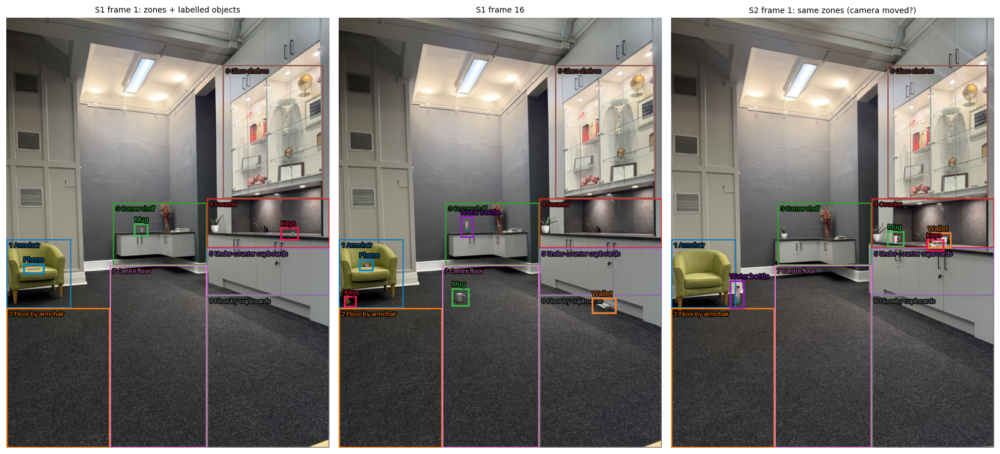

In [ ]:
# ✏️ EDIT HERE if the camera view changed ------------------------------------------
ZONES = {   #  name                       x1     y1     x2     y2   (fractions of width / height)
    "Armchair":                       (0.000, 0.515, 0.200, 0.675),
    "Floor by armchair":              (0.000, 0.675, 0.320, 1.000),
    "Corner shelf":                   (0.330, 0.430, 0.620, 0.575),
    "Counter":                        (0.620, 0.420, 1.000, 0.535),
    "Under-counter cupboards":        (0.620, 0.535, 1.000, 0.645),
    "Glass shelves":                  (0.670, 0.110, 0.980, 0.420),
    "Centre floor":                   (0.320, 0.575, 0.620, 1.000),
    "Floor by cupboards":             (0.620, 0.645, 1.000, 1.000),
}
SPOKEN = {  # how each zone is said aloud
    "Armchair": "on the armchair", "Floor by armchair": "on the floor by the armchair",
    "Corner shelf": "on the corner shelf", "Counter": "on the counter",
    "Under-counter cupboards": "by the under-counter cupboards", "Glass shelves": "on the glass shelves",
    "Centre floor": "on the floor in the middle of the room", "Floor by cupboards": "on the floor by the cupboards",
}
# -----------------------------------------------------------------------------------
ZONE_NAMES = list(ZONES)
ZONE_COLORS = plt.cm.tab10(np.arange(len(ZONES)))[:, :3]

def zone_of_point(fx, fy):
    inside = [(z, (b[2] - b[0]) * (b[3] - b[1])) for z, b in ZONES.items()
              if b[0] <= fx <= b[2] and b[1] <= fy <= b[3]]
    if inside:
        return min(inside, key=lambda t: t[1])[0]           # smallest containing box wins
    def dist(b):
        dx = max(b[0] - fx, 0, fx - b[2]); dy = max(b[1] - fy, 0, fy - b[3])
        return math.hypot(dx, dy)
    return min(ZONES, key=lambda z: dist(ZONES[z]))

def zone_of_box(x1, y1, x2, y2, W, H):
    return zone_of_point((x1 + x2) / 2 / W, (y1 + y2) / 2 / H)

def draw_zones(img):
    d = ImageDraw.Draw(img); W, H = img.size; f = _font(max(12, W // 50))
    for i, (z, (a, b, c, e)) in enumerate(ZONES.items()):
        col = tuple(int(255 * v) for v in ZONE_COLORS[i])
        d.rectangle([a * W, b * H, c * W, e * H], outline=col, width=3)
        d.text((a * W + 6, b * H + 4), f"{i + 1} {z}", fill=col, font=f, stroke_width=2, stroke_fill=(0, 0, 0))
    return img

first = SESS["s1"]["frames"].frame.iloc[0]
mid = SESS["s1"]["frames"].frame.iloc[len(SESS["s1"]["frames"]) * 3 // 4]
fig, axs = plt.subplots(1, 3 if "s2" in SESS else 2, figsize=(16, 8))
show_frame("s1", first, zones=True, ax=axs[0], title=f"S1 frame {first}: zones + labelled objects")
show_frame("s1", mid, zones=True, ax=axs[1], title=f"S1 frame {mid}")
if "s2" in SESS:
    f2 = SESS["s2"]["frames"].frame.iloc[0]
    show_frame("s2", f2, zones=True, ax=axs[2], title=f"S2 frame {f2}: same zones (camera moved?)")
plt.tight_layout(); plt.show()

---
## 5. Ground truth: where each object really was, frame by frame
For every frame and object the state is one of:
* **visible**: labelled box, not touching a person. Its zone comes from the box centre.
* **with_person**: the box overlaps a person by at least 50 % (carried, or blocked). These frames are **left out** of calibration and test questions, as in the original protocol.
* **not_visible**: no box (removed, hidden or not yet in the room).

The table below shows each object's **placements**: runs of frames in the same state and zone.

In [ ]:
def overlap_frac(b, others):
    """Fraction of box b covered by the union-ish (max) of `others`."""
    x1, y1, x2, y2 = b
    a = max(1e-6, (x2 - x1) * (y2 - y1)); best = 0
    for o in others:
        iw = max(0, min(x2, o[2]) - max(x1, o[0])); ih = max(0, min(y2, o[3]) - max(y1, o[1]))
        best = max(best, iw * ih / a)
    return best

PERSON_OVERLAP = 0.5

def gt_from_boxes(sk):
    S = SESS[sk]; rows = []
    for fr in S["frames"].itertuples():
        g = S["boxes"][S["boxes"].frame == fr.frame] if not S["boxes"].empty else pd.DataFrame()
        persons = PERSON_BOXES.get((sk, fr.frame), [])
        for obj in OBJECTS:
            ob = g[g.label == obj] if len(g) else g
            if len(ob) == 0:
                rows.append(dict(frame=fr.frame, time=fr.time, object=obj, state="not_visible", zone=None, box=None))
                continue
            ob = ob.assign(a=(ob.x2 - ob.x1) * (ob.y2 - ob.y1)).sort_values("a").iloc[-1]
            box = (ob.x1, ob.y1, ob.x2, ob.y2)
            state = "with_person" if overlap_frac(box, persons) >= PERSON_OVERLAP else "visible"
            rows.append(dict(frame=fr.frame, time=fr.time, object=obj, state=state,
                             zone=zone_of_box(*box, fr.W, fr.H), box=box))
    return pd.DataFrame(rows)

def placements(gt):
    out = []
    for obj, g in gt.sort_values("frame").groupby("object", sort=False):
        lab = g.apply(lambda r: r.zone if r.state == "visible" else r.state, axis=1).tolist()
        frames = g.frame.tolist(); start = 0
        for i in range(1, len(lab) + 1):
            if i == len(lab) or lab[i] != lab[start]:
                out.append(dict(object=obj, state_or_zone=lab[start], first=frames[start], last=frames[i - 1], n=i - start))
                start = i
    return pd.DataFrame(out)

GT = {sk: gt_from_boxes(sk) for sk, S in SESS.items() if S["labelled"]}
GT_SOURCE = {sk: "Roboflow boxes" for sk in GT}

for sk, g in GT.items():
    print(f"━━ {sk.upper()} placements (from {GT_SOURCE[sk]}) ━━")
    display(placements(g).set_index(["object", "state_or_zone"]))

USUAL_ZONE = (GT["s1"][GT["s1"].state == "visible"].groupby("object").zone
              .agg(lambda s: s.value_counts().index[0]).to_dict())
print("Usual S1 zone per object (used by the prior baseline):")
for o in OBJECTS:
    print(f"   {o:13s} → {USUAL_ZONE.get(o, '—')}")

━━ S1 placements (from Roboflow boxes) ━━


first  last   n
object       state_or_zone                      
Keys         Counter                 1     1   1
             with_person             2     2   1
             Armchair                3    18  16
             with_person            19    19   1
             Armchair               20    20   1
Wallet       not_visible             1    12  12
             with_person            13    13   1
             Floor by cupboards     14    20   7
Mug          Corner shelf            1     6   6
             not_visible             7     7   1
             with_person             8    10   3
             Centre floor           11    16   6
             not_visible            17    20   4
Phone        Armchair                1    10  10
             with_person            11    11   1
             Armchair               12    17   6
             with_person            18    18   1
             Floor by armchair      19    20   2
Water bottle not_visible             1     3   3
             with_person             4     4   1
             Counter                 5    14  10
             with_person            15    15   1
             Corner shelf           16    20   5

━━ S2 placements (from Roboflow boxes) ━━


first  last   n
object       state_or_zone                 
Keys         Counter            1     3   3
             not_visible        4     4   1
             Counter            5     8   4
             with_person        9     9   1
             not_visible       10    12   3
...                           ...   ...  ..
Water bottle Armchair           1    33  33
             with_person       34    34   1
             Counter           35    49  15
             with_person       50    51   2
             Corner shelf      52    60   9

[65 rows x 3 columns]

Usual S1 zone per object (used by the prior baseline):
   Keys          → Armchair
   Wallet        → Floor by cupboards
   Mug           → Corner shelf
   Phone         → Armchair
   Water bottle  → Counter


### 5.1 Placement log (optional cross-check)
The log written during recording is loaded and shown. If it can be read automatically, it is compared with the zones taken from the boxes. Disagreements usually mean a zone box needs a small adjustment, or a label is wrong.
If **Session 2 has no Roboflow labels**, the log becomes S2's ground truth. Check the parsed table carefully in that case.

The parser understands either **one row per move** (time or frame, object, zone, notes) or **one row per frame with one column per object**. Words like *hidden / under* mean hidden, *removed / not in room* mean absent, and *carried / in hand* mean with a person.

In [ ]:
def find_logs():
    root = LOCAL.get("log")
    files = []
    if root is not None:
        for pat in LOG_PATTERNS:
            files = sorted(root.rglob(pat))
            if files:
                break
    for k in ["s1", "s2"]:                                     # a log may also sit next to the photos
        if LOCAL.get(k) is not None:
            files += sorted(LOCAL[k].rglob("*.xlsx"))
    return list(dict.fromkeys(files))

ZONE_ALIASES = [   # checked in this order; the more specific phrases come first
    ("Floor by armchair", ["floor by armchair", "floor by the armchair", "floor near armchair", "next to armchair", "beside armchair", "by the armchair", "by armchair"]),
    ("Floor by cupboards", ["floor by cupboard", "floor by the cupboard", "floor near cupboard", "in front of cupboard", "by the cupboards", "by cupboards"]),
    ("Under-counter cupboards", ["under-counter", "under counter", "undercounter", "cupboard"]),
    ("Corner shelf", ["corner shelf", "corner"]),
    ("Glass shelves", ["glass", "display"]),
    ("Centre floor", ["centre floor", "center floor", "centre", "center", "middle"]),
    ("Counter", ["counter", "sink", "kitchen"]),
    ("Armchair", ["armchair", "arm chair", "chair"]),
]

def match_zone(text):
    t = str(text).lower()
    m = re.search(r"\bzone\s*(\d)\b|^\s*(\d)\s*$", t)
    if m:
        i = int(m.group(1) or m.group(2))
        if 1 <= i <= len(ZONE_NAMES):
            return ZONE_NAMES[i - 1]
    for z, al in ZONE_ALIASES:
        if any(a in t for a in al):
            return z
    c = difflib.get_close_matches(t.strip(), [z.lower() for z in ZONE_NAMES], n=1, cutoff=0.6)
    return ZONE_NAMES[[z.lower() for z in ZONE_NAMES].index(c[0])] if c else None

def classify_text(text):
    t = str(text).lower()
    t_wo = re.sub(r"under[- ]?counter", "", t)
    if any(k in t for k in ["carr", "in hand", "holding", "picked up", "moving"]):
        return "with_person"
    if any(k in t for k in ["remov", "not in room", "not in the room", "out of room", "out of the room", "absent", "taken out", "gone", "left the room", "not yet"]):
        return "not_visible"
    if any(k in t_wo for k in ["hidden", "hide", "under", "covered", "behind", "inside", "not visible", "occlu", "pushed"]):
        return "hidden"
    return "visible"

def _secs(v):
    """Seconds after midnight from a time-like cell, or None."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    if isinstance(v, (dt.datetime, pd.Timestamp)):
        return v.hour * 3600 + v.minute * 60 + v.second
    if isinstance(v, dt.time):
        return v.hour * 3600 + v.minute * 60 + v.second
    if isinstance(v, (int, float)) and 0 <= v < 1:            # Excel fraction of a day
        return int(round(v * 86400))
    m = re.search(r"(\d{1,2})[:.h](\d{2})(?:[:.](\d{2}))?\s*([ap]\.?m)?", str(v).lower())
    if not m:
        return None
    h, mi, s, ap = int(m.group(1)), int(m.group(2)), int(m.group(3) or 0), m.group(4)
    if ap:
        h = h % 12 + (12 if ap.startswith("p") else 0)
    return h * 3600 + mi * 60 + s

def _frame_from_cell(v):
    m = re.search(r"img[_\s-]*(\d+)", str(v).lower()) or re.fullmatch(r"\s*(\d+)(?:\.0)?\s*", str(v))
    return int(m.group(1)) if m else None

def _session_of(text):
    t = _norm(text)
    if re.search(r"(session|s)2", t): return "s2"
    if re.search(r"(session|s)1", t): return "s1"
    return None

def parse_log_file(path):
    events = []
    for sheet, raw in pd.read_excel(path, sheet_name=None, header=None).items():
        raw = raw.dropna(how="all").dropna(axis=1, how="all")
        if raw.empty:
            continue
        hdr_i = next((i for i in range(min(10, len(raw)))
                      if sum(any(k in str(c).lower() for k in ["object", "item", "zone", "location", "time", "frame", "img", "image"])
                             for c in raw.iloc[i]) >= 2), 0)
        df = raw.iloc[hdr_i + 1:].copy(); df.columns = [str(c).strip() for c in raw.iloc[hdr_i]]
        cols = {c.lower(): c for c in df.columns}
        pick = lambda *keys: next((cols[c] for c in cols if any(k in c for k in keys)), None)
        c_obj, c_zone = pick("object", "item"), pick("zone", "location", "where", "place")
        c_time, c_frame, c_sess = pick("time", "clock"), pick("frame", "img", "image", "photo"), pick("session")
        c_notes = [cols[c] for c in cols if any(k in c for k in ["visib", "status", "state", "action", "note", "comment", "hidden"])]
        obj_cols = {c: canon_label(c) for c in df.columns if canon_label(c) in OBJECTS}
        sess_default = _session_of(sheet) or _session_of(Path(path).stem)
        for _, r in df.iterrows():
            sess = _session_of(r[c_sess]) if c_sess else None
            sess = sess or sess_default
            fno = _frame_from_cell(r[c_frame]) if c_frame else None
            secs = _secs(r[c_time]) if c_time else None
            if len(obj_cols) >= 3:                                   # wide: one column per object
                for c, obj in obj_cols.items():
                    if pd.notna(r[c]) and str(r[c]).strip():
                        events.append(dict(session=sess, frame=fno, secs=secs, object=obj, text=str(r[c]), sheet=sheet))
            elif c_obj is not None and pd.notna(r[c_obj]) and canon_label(r[c_obj]) in OBJECTS:   # long: one row per move
                text = " ".join(str(r[c]) for c in ([c_zone] if c_zone else []) + c_notes if pd.notna(r[c]))
                events.append(dict(session=sess, frame=fno, secs=secs, object=canon_label(r[c_obj]), text=text, sheet=sheet))
    return pd.DataFrame(events)

def log_to_gt(ev, sk):
    """Turn move events into one state per (frame, object); objects are 'not_visible' before their first event."""
    S = SESS[sk]; fr = S["frames"]
    ev = ev[(ev.session == sk) | ev.session.isna()].copy()
    if ev.empty:
        return None
    fsecs = fr.time.apply(lambda t: t.hour * 3600 + t.minute * 60 + t.second if pd.notna(t) else None)
    def to_frame(r):
        if r.frame is not None and not pd.isna(r.frame):
            return int(r.frame)
        if r.secs is not None and not pd.isna(r.secs) and fsecs.notna().any():
            later = fr.frame[fsecs >= r.secs - 15]                 # first photo taken at/after the move (15 s slack)
            return int(later.iloc[0]) if len(later) else None
        return None
    ev["start"] = ev.apply(to_frame, axis=1)
    ev = ev.dropna(subset=["start"])
    rows = []
    for obj in OBJECTS:
        e = ev[ev.object == obj].sort_values("start")
        for f in fr.itertuples():
            cur = e[e.start <= f.frame]
            if cur.empty:
                rows.append(dict(frame=f.frame, time=f.time, object=obj, state="not_visible", zone=None, box=None)); continue
            text = cur.iloc[-1].text
            st = classify_text(text); z = match_zone(text)
            if st == "visible" and z is None:
                st = "not_visible"
            rows.append(dict(frame=f.frame, time=f.time, object=obj,
                             state={"hidden": "not_visible"}.get(st, st), zone=z if st == "visible" else None, box=None,
                             log_text=text))
    return pd.DataFrame(rows)

LOG_EVENTS = None
log_files = find_logs()
if not log_files:
    print("No placement-log .xlsx found (optional).")
for lf in log_files:
    print(f"━━ {lf.name} ━━")
    for sh, df in pd.read_excel(lf, sheet_name=None).items():
        print(f"sheet '{sh}': {df.shape[0]} rows × {df.shape[1]} cols"); display(df.head(8))
    try:
        ev = parse_log_file(lf)
        if len(ev):
            ev["file"] = lf.name
            LOG_EVENTS = ev if LOG_EVENTS is None else pd.concat([LOG_EVENTS, ev], ignore_index=True)
            print(f"✓ parsed {len(ev)} events from {lf.name} (sessions: {ev.session.fillna('?').value_counts().to_dict()})")
        else:
            print("⚠️ could not recognise the columns of", lf.name)
    except Exception as e:
        print("⚠️ could not parse", lf.name, "→", e)

if LOG_EVENTS is not None:
    for sk in SESS:
        lg = log_to_gt(LOG_EVENTS, sk)
        if lg is None:
            continue
        if sk in GT:      # cross-check boxes vs log
            m = GT[sk].merge(lg, on=["frame", "object"], suffixes=("_box", "_log"))
            both = m[(m.state_box == "visible") & (m.state_log == "visible")]
            agree = (both.zone_box == both.zone_log).mean() if len(both) else float("nan")
            print(f"\n{sk.upper()}: zone agreement boxes vs log on {len(both)} frame-object pairs = {agree:.0%}")
            bad = both[both.zone_box != both.zone_log]
            if len(bad):
                display(bad.groupby(["object", "zone_box", "zone_log"]).frame.agg(["min", "max", "count"]))
        else:             # no Roboflow labels for this session → the log is the ground truth
            GT[sk] = lg; GT_SOURCE[sk] = "placement log"
            print(f"\n{sk.upper()} ground truth taken from the placement log. Check these placements:")
            display(placements(lg).set_index(["object", "state_or_zone"]))

━━ placement_log_v3.xlsx ━━
sheet 'README': 38 rows × 1 cols


,"Placement log — Did I lose it here, or there?"
0,Draft v0.3 · 15 Nov 2026 · owner: Khethiwe · e...
1,NaN
2,WHAT EACH TAB IS FOR
3,Pilot Script — the actor's run sheet for the 2...
4,Placement Log — one row per change in the scen...
5,Questions — the 'Where is my …?' test queries....
6,Objects / Zones / Sessions — setup: the 5 obje...
7,NaN


sheet 'S1 Script': 61 rows × 10 cols


,8,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,"20 photos, one every 30 s (9 min 30 s). Gogo s...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Story,"Gogo (the grandmother, played by the actor) go...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Rest spots,"A = beside the glass shelves (zone 6, never us...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Cues,The logger calls: PHOTO (shutter fires) → 5 s ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Rules,"One move per GO. Walk calmly, the way she woul...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,If late,If PHOTO fires while she is still walking or t...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Never,Nothing goes on the glass shelves (zone 6). Do...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


sheet 'Placement Log': 65 rows × 25 cols


,Placement Log,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24
0,One row per change. Type Hands in / Hands out ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Tags: small, distant, partly hidden, dark on d...",NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Event ID,Session,Object ID,Object,Zone (0–8),Zone name,State,Hand In Time,Zone after movement,Zone name after movement,State after movement,Time when changed,Hand Out,NaN,Planned (min from start),Planned clock,Hands in,Hands out (state starts),Until (next change),Usual place?,Hard case,Seen in frames? (check later),Logged by,Notes,key (helper)
3,EX-01,EX,O1,Keys,1,Armchair,Visible,NaN,NaN,,Visible,NaN,NaN,NaN,2,14:02:00,14:02:10,14:02:25,14:32:15,N,NaN,NaN,NaN,Keys left on the armchair,EX|O1|14:02:25
4,EX-02,EX,O1,Keys,1,Armchair,Hidden,NaN,NaN,NaN,Hidden,NaN,NaN,NaN,32,14:32:00,14:32:15,14:32:40,end,N,NaN,NaN,NaN,Pushed under the armchair,EX|O1|14:32:40
5,P-01,S1,O1,Keys,4,Counter,Visible,00:52:29,1,Armchair,Visible,00:52:15,00:53:11,NaN,-2,NaN,NaN,NaN,NaN,Y,Small,NaN,NaN,"Setup: lying flat on the counter, near the fro...",NaN
6,P-06,S1,O5,Water bottle,0,Out of room,Removed,00:53:19,4,Counter,Visible,00:53:30,00:53:41,NaN,1.583333,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,Move 2: Water bottle: brought in → Counter (fi...,NaN
7,P-03,S1,O3,Phone,1,Armchair,Visible,00:54:12,1,Armchair,Partly hidden,00:54:56,in frame,NaN,-2,NaN,NaN,NaN,NaN,N,Distant,NaN,NaN,"Setup: on the corner shelf, handle facing the ...",NaN


... (35 outputs left out)

,"S2 Notes — how the Session 2 log was built, and where the scenario and the photos disagree",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,Built 17 Nov 2026 from here_or_there-S2_coco.z...,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,S2 TABS,NaN,NaN,NaN,NaN
3,• S2 Placement Log — one row per change: 10 ch...,NaN,NaN,NaN,NaN
4,• S2 Frame states — where every object is in e...,NaN,NaN,NaN,NaN
5,• S2 Notes — this tab.,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN
7,STARTING STATES (before IMG001),NaN,NaN,NaN,NaN


/tmp/ipykernel_1451/1175530.py:152: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  LOG_EVENTS = ev if LOG_EVENTS is None else pd.concat([LOG_EVENTS, ev], ignore_index=True)


✓ parsed 426 events from placement_log_v4_corrected_with_S2.xlsx (sessions: {'s2': 426})

S1: zone agreement boxes vs log on 0 frame-object pairs = nan%

S2: zone agreement boxes vs log on 150 frame-object pairs = 62%


min  max  count
object       zone_box                zone_log                           
Keys         Counter                 Armchair              3    7      3
Mug          Corner shelf            Centre floor          9   13      3
             Counter                 Corner shelf          2    6      3
Phone        Under-counter cupboards Armchair              6    6      1
                                     Counter               5   30     16
Wallet       Counter                 Floor by cupboards   17   19      2
Water bottle Armchair                Corner shelf         17   19      2
                                     Counter               6   13      5
                                     Floor by armchair     1   32     22

---
## 6. Draw the test questions *before* looking at Session 2
A question is *"Where is my <object>?"* asked at the moment frame *t* is taken. The expected answer comes from the ground truth, using frames up to *t* only:

| expected answer | when |
|---|---|
| **visible now** in zone Z | the object is visible in frame *t* |
| **last seen** in zone Z at time T | not visible at *t*, but visible at some earlier frame |
| **not seen** | never visible up to *t* |

**Design** (fixed in advance, seed 2026): 10 questions per object, spread over all placements. Every placement gets at least one question, and the rest are shared by placement length. Frames before an object first appears are always included, and frames with a person are skipped.
The same design is also applied to S1. Those S1 questions only give an early idea of the results; they are not the test.

In [ ]:
N_PER_OBJECT = 10

def expected_answer(states_upto):
    """states_upto: rows for ONE object with frame <= t (sorted). Uses only the past."""
    vis = states_upto[states_upto.state == "visible"]
    t = states_upto.frame.max()
    if vis.empty:
        return "not_seen", None, None
    last = vis.iloc[-1]
    return ("visible" if last.frame == t else "last_seen"), last.zone, int(last.frame)

def design_queries(gt, sk, n_per=N_PER_OBJECT, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for obj in OBJECTS:
        g = gt[gt.object == obj].sort_values("frame").reset_index(drop=True)
        first_vis = g.frame[g.state == "visible"].min() if (g.state == "visible").any() else np.inf
        lab = [("not_yet" if (r.state != "visible" and r.frame < first_vis) else (r.zone if r.state == "visible" else r.state))
               for r in g.itertuples()]
        runs, s = [], 0
        for i in range(1, len(lab) + 1):
            if i == len(lab) or lab[i] != lab[s]:
                if lab[s] != "with_person":
                    runs.append(dict(label=lab[s], frames=g.frame[s:i].tolist()))
                s = i
        if not runs:
            continue
        total = sum(len(r["frames"]) for r in runs)
        n = min(n_per, total)
        alloc = [0] * len(runs)
        must = [i for i, r in enumerate(runs) if r["label"] == "not_yet"]   # always ask at least once before it appears
        order = [i for i in range(len(runs)) if i not in must]
        if len(must) + len(order) > n:                        # more placements than questions: keep longer ones (randomly)
            w = np.array([len(runs[i]["frames"]) for i in order], float)
            order = list(rng.choice(order, size=n - len(must), replace=False, p=w / w.sum()))
        for i in must + order:
            alloc[i] = 1
        while sum(alloc) < n:                                 # share the rest by length (largest remainder)
            cand = [i for i in range(len(runs)) if alloc[i] < len(runs[i]["frames"])]
            if not cand:
                break
            i = max(cand, key=lambda i: len(runs[i]["frames"]) * n / total - alloc[i])
            alloc[i] += 1
        for r, k in zip(runs, alloc):
            if k:
                for f in sorted(rng.choice(r["frames"], size=k, replace=False)):
                    st, z, lf = expected_answer(g[g.frame <= f])
                    out.append(dict(session=sk, object=obj, t=int(f), placement=r["label"],
                                    exp_state=st, exp_zone=z, exp_frame=lf))
    q = pd.DataFrame(out).sort_values(["object", "t"]).reset_index(drop=True)
    q.insert(0, "qid", [f"{sk.upper()}-{i + 1:02d}" for i in range(len(q))])
    return q

QUERIES = {}
for sk in GT:
    path = CACHE / f"queries_{sk.upper()}.csv"
    q = design_queries(GT[sk], sk)
    if path.exists():
        old = pd.read_csv(path)
        if not (len(old) == len(q) and (old.t.values == q.t.values).all()
                and (old.exp_zone.fillna("") == q.exp_zone.fillna("")).all()):
            print(f"ℹ️ {path.name} changed (ground truth or zones changed) → rewritten")
    q.to_csv(path, index=False)
    q = pd.read_csv(path)
    QUERIES[sk] = q
    h = hashlib.sha1(q[["object", "t"]].to_csv(index=False).encode()).hexdigest()[:10]
    print(f"━━ {sk.upper()}: {len(q)} questions  (saved {path.name}, sha1 {h}) ━━")
    display(pd.crosstab(q.object, q.exp_state, margins=True))

━━ S1: 50 questions  (saved queries_S1.csv, sha1 70beefc5e9) ━━


exp_state,last_seen,not_seen,visible,All
object,,,,
Keys,0,0,10,10
Mug,3,0,7,10
Phone,0,0,10,10
Wallet,0,7,3,10
Water bottle,0,2,8,10
All,3,9,38,50


━━ S2: 50 questions  (saved queries_S2.csv, sha1 016d3531bd) ━━


exp_state,last_seen,not_seen,visible,All
object,,,,
Keys,6,0,4,10
Mug,2,0,8,10
Phone,1,1,8,10
Wallet,2,0,8,10
Water bottle,0,0,10,10
All,11,1,38,50


---
## 7. Training data: full-resolution tiles + copy-paste
* **Tiles:** each 3024 × 4032 photo is cut into 640 × 640 tiles that overlap by 224 px. Every object fits completely in at least one tile.
* **Real tiles:** every tile that contains an object, plus a few empty tiles (carpet, shelves, the glass display) so the model learns what is *not* an object.
* **Copy-paste tiles:** object crops cut from the labelled boxes are pasted at random places, sizes (0.7–1.4×) and brightness levels (0.55–1.3×) onto other tiles. Session 1 shows each object in only 2–4 places, so without this the detector would learn the places instead of the objects.
* **Registration photos with a Roboflow export** (optional) are added as extra crops for pasting, shrunk to the size the objects have in the room.

In [ ]:
TILE, OVERLAP = 640, 224
NEG_PER_FRAME = 8
N_SYNTH = 700
CLASS_ID = {o: i for i, o in enumerate(OBJECTS)}

def tile_origins(W, H, tile=TILE, overlap=OVERLAP):
    step = tile - overlap
    xs = list(range(0, max(W - tile, 0) + 1, step)); ys = list(range(0, max(H - tile, 0) + 1, step))
    if xs[-1] != max(W - tile, 0): xs.append(max(W - tile, 0))
    if ys[-1] != max(H - tile, 0): ys.append(max(H - tile, 0))
    return [(x, y) for y in ys for x in xs]

def boxes_in_tile(boxes, x0, y0, tile=TILE):
    """Return (kept boxes in tile coords, ambiguous?) ; kept = ≥60% of the box inside the tile."""
    kept, ambiguous = [], False
    for lab, x1, y1, x2, y2 in boxes:
        ix1, iy1, ix2, iy2 = max(x1, x0), max(y1, y0), min(x2, x0 + tile), min(y2, y0 + tile)
        if ix2 <= ix1 or iy2 <= iy1:
            continue
        frac = (ix2 - ix1) * (iy2 - iy1) / max(1e-6, (x2 - x1) * (y2 - y1))
        if frac >= 0.6:
            kept.append((lab, ix1 - x0, iy1 - y0, ix2 - x0, iy2 - y0))
        elif frac > 0.1:
            ambiguous = True
    return kept, ambiguous

def object_boxes(sk, frame):
    b = SESS[sk]["boxes"]
    g = b[(b.frame == frame) & (b.label.isin(OBJECTS))]
    return [(r.label, r.x1, r.y1, r.x2, r.y2) for r in g.itertuples()]

def load_registration_crops():
    """Crops from a Roboflow export of the registration photos, if there is one."""
    root = LOCAL.get("registration"); crops = []
    if root is None:
        return crops
    for jf in root.rglob("*.json"):
        try:
            d = json.load(open(jf)); cats = {c["id"]: canon_label(c["name"]) for c in d["categories"]}
        except Exception:
            continue
        ims = {i["id"]: i for i in d.get("images", [])}
        for a in d.get("annotations", []):
            lab = cats.get(a["category_id"]); im = ims.get(a["image_id"])
            if lab in OBJECTS and im and (jf.parent / im["file_name"]).exists():
                img = ImageOps.exif_transpose(Image.open(jf.parent / im["file_name"])).convert("RGB")
                if img.size != (im["width"], im["height"]):
                    img = Image.open(jf.parent / im["file_name"]).convert("RGB")
                x, y, w, h = a["bbox"]
                crops.append((lab, np.asarray(img.crop((x, y, x + w, y + h))), "registration"))
    return crops

REG_CROPS = load_registration_crops()
print(f"registration crops available for copy-paste: {len(REG_CROPS)}"
      + ("" if REG_CROPS else "  (no Roboflow export in the registration folder; S1 crops only)"))

def paste_object(canvas, crop, x, y, rng):
    """Alpha-blend `crop` into `canvas` at (x, y) with soft edges and random brightness."""
    h, w = crop.shape[:2]
    c = crop.astype(np.float32) * rng.uniform(0.55, 1.3) + rng.uniform(-12, 12)
    mask = np.ones((h, w), np.float32); e = max(1, min(h, w) // 8)
    ramp = np.linspace(0.15, 1, e)
    mask[:e] *= ramp[:, None]; mask[-e:] *= ramp[::-1][:, None]
    mask[:, :e] *= ramp[None]; mask[:, -e:] *= ramp[::-1][None]
    region = canvas[y:y + h, x:x + w].astype(np.float32)
    canvas[y:y + h, x:x + w] = np.clip(region * (1 - mask[..., None]) + c * mask[..., None], 0, 255).astype(np.uint8)

def build_dataset(name, train_frames, val_frames, sk="s1", n_synth=N_SYNTH, seed=SEED):
    """Write a YOLO dataset (tiles) for the given S1 frames. Returns the path of data.yaml."""
    rng = np.random.default_rng(seed)
    root = WORK / "datasets" / name
    if root.exists():
        shutil.rmtree(root)
    for split in ["train", "val"]:
        (root / "images" / split).mkdir(parents=True); (root / "labels" / split).mkdir(parents=True)
    counts = Counter()

    def save(arr, labels, split, stem):
        Image.fromarray(arr).save(root / "images" / split / f"{stem}.jpg", quality=92)
        with open(root / "labels" / split / f"{stem}.txt", "w") as fh:
            for lab, x1, y1, x2, y2 in labels:
                th, tw = arr.shape[:2]
                fh.write(f"{CLASS_ID[lab]} {(x1 + x2) / 2 / tw:.6f} {(y1 + y2) / 2 / th:.6f} {(x2 - x1) / tw:.6f} {(y2 - y1) / th:.6f}\n")
                counts[split, lab] += 1
        counts[split, "tiles"] += 1

    crops, backgrounds = list(REG_CROPS), []
    for split, frames in [("train", train_frames), ("val", val_frames)]:
        for f in frames:
            img = np.asarray(open_frame(sk, f)); H, W = img.shape[:2]
            boxes = object_boxes(sk, f)
            if split == "train":
                for lab, x1, y1, x2, y2 in boxes:
                    p = 4
                    crops.append((lab, img[int(max(0, y1 - p)):int(min(H, y2 + p)), int(max(0, x1 - p)):int(min(W, x2 + p))].copy(), "s1"))
                backgrounds.append((img, boxes))
            pos, neg = [], []
            for x0, y0 in tile_origins(W, H):
                kept, amb = boxes_in_tile(boxes, x0, y0)
                if amb:
                    continue
                (pos if kept else neg).append((x0, y0, kept))
            negs = [neg[i] for i in rng.choice(len(neg), size=min(NEG_PER_FRAME, len(neg)), replace=False)] if neg else []
            for x0, y0, kept in pos + negs:
                save(img[y0:y0 + TILE, x0:x0 + TILE], kept, split, f"{sk}_f{f}_{x0}_{y0}")

    # size of each object in the room, to scale registration crops
    room_size = defaultdict(list)
    for lab, c, src in crops:
        if src == "s1":
            room_size[lab].append(max(c.shape[:2]))
    for i in range(n_synth):
        img, boxes = backgrounds[rng.integers(len(backgrounds))]; H, W = img.shape[:2]
        for _ in range(20):                                    # find a background tile with no cut objects
            x0 = int(rng.integers(0, W - TILE + 1)); y0 = int(rng.integers(int(0.1 * H), H - TILE + 1))
            kept, amb = boxes_in_tile(boxes, x0, y0)
            if not amb:
                break
        tile = img[y0:y0 + TILE, x0:x0 + TILE].copy()
        labels, placed = list(kept), []
        for _ in range(int(rng.integers(1, 4))):
            lab, crop, src = crops[rng.integers(len(crops))]
            if src == "registration" and room_size[lab]:
                target = rng.choice(room_size[lab]) * rng.uniform(0.7, 1.4)
            else:
                target = max(crop.shape[:2]) * rng.uniform(0.7, 1.4)
            s = max(8, target) / max(crop.shape[:2])
            ch, cw = max(6, int(crop.shape[0] * s)), max(6, int(crop.shape[1] * s))
            if ch >= TILE - 4 or cw >= TILE - 4:
                continue
            c = np.asarray(Image.fromarray(crop).resize((cw, ch), Image.BILINEAR))
            if rng.random() < 0.5:
                c = c[:, ::-1]
            for _ in range(10):
                px, py = int(rng.integers(0, TILE - cw)), int(rng.integers(0, TILE - ch))
                nb = (px, py, px + cw, py + ch)
                if all(overlap_frac(nb, [p]) == 0 for p in placed):
                    break
            paste_object(tile, np.ascontiguousarray(c), px, py, rng)
            placed.append(nb)
            labels = [l for l in labels if overlap_frac(l[1:], [nb]) < 0.3]   # real objects now covered
            labels.append((lab, *nb))
        save(tile, labels, "train", f"synth_{i:04d}")

    yaml = root / "data.yaml"
    yaml.write_text(f"path: {root}\ntrain: images/train\nval: images/val\nnames:\n" +
                    "".join(f"  {i}: {o}\n" for i, o in enumerate(OBJECTS)))
    summary = pd.DataFrame({sp: {k: counts[sp, k] for k in ["tiles"] + OBJECTS} for sp in ["train", "val"]})
    return yaml, summary

def show_tiles(yaml, n=12, seed=0):
    root = Path(str(yaml)).parent
    ims = sorted((root / "images" / "train").glob("*.jpg"))
    rng = random.Random(seed)
    pick = rng.sample([p for p in ims if not p.stem.startswith("synth")], min(n // 2, len(ims))) + \
           rng.sample([p for p in ims if p.stem.startswith("synth")], n // 2)
    fig, axs = plt.subplots(2, n // 2, figsize=(2.6 * n // 2, 5.6))
    for ax, p in zip(axs.flat, pick):
        im = Image.open(p).convert("RGB"); d = ImageDraw.Draw(im)
        for line in open(root / "labels" / "train" / f"{p.stem}.txt"):
            c, cx, cy, w, h = map(float, line.split())
            lab = OBJECTS[int(c)]
            d.rectangle([(cx - w / 2) * TILE - 6, (cy - h / 2) * TILE - 6, (cx + w / 2) * TILE + 6, (cy + h / 2) * TILE + 6],
                        outline=OBJ_COLORS[lab], width=4)
        ax.imshow(im); ax.axis("off"); ax.set_title("pasted" if p.stem.startswith("synth") else "real", fontsize=8)
    plt.suptitle("Example training tiles: top row = real tiles (incl. empty ones), bottom row = copy-paste tiles", fontsize=10)
    plt.tight_layout(); plt.show()

registration crops available for copy-paste: 0  (no Roboflow export in the registration folder; S1 crops only)


---
## 8. Train the detector
* **2-fold cross-validation on S1:** model A trains on frames 1–10 and is tested on 11–20; model B the reverse. Their *out-of-fold* detections are used to choose the threshold τ (section 10). They are honest because each model never saw the frames it is tested on.
* **Final model:** trained on **all** S1 frames, with the same settings. This is the model used on Session 2 and in the demo.

Trained weights are saved to `My Drive/PauseFind_cache/models`. Set `RETRAIN = True` to train again.


▶ cv_A: train on S1 frames 1–10, test on 11–20
━━ cv_A: dataset ━━


,tiles,Keys,Wallet,Mug,Phone,Water bottle
train,824,422,0,364,444,313
val,157,20,32,12,10,14


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/pf_work/datasets/cv_A/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.5, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cv_A, nbs=64, nms=None, opset=None, optimize=Fals

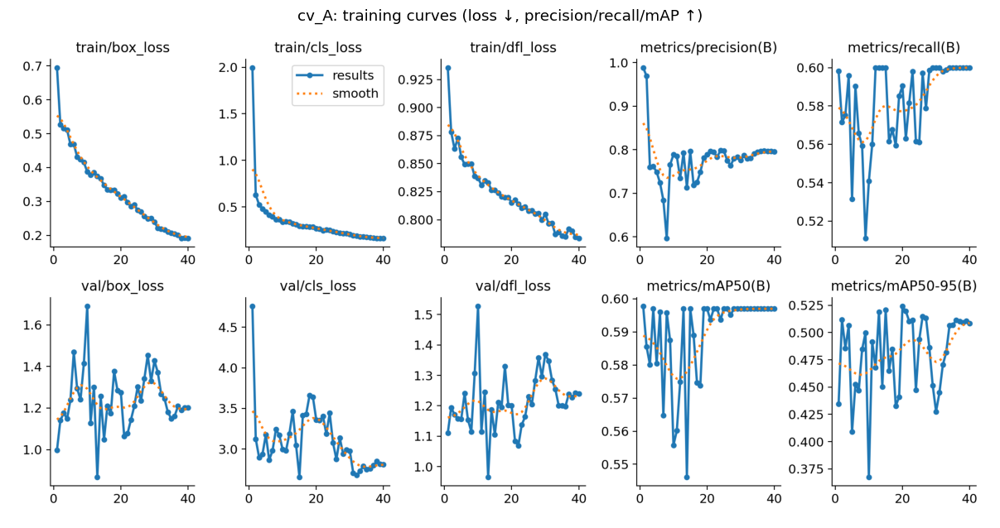


▶ cv_B: train on S1 frames 11–20, test on 1–10
━━ cv_B: dataset ━━


,tiles,Keys,Wallet,Mug,Phone,Water bottle
train,857,335,304,247,337,357
val,124,11,0,18,10,14


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/pf_work/datasets/cv_B/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.5, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cv_B, nbs=64, nms=None, opset=None, optimize=Fals

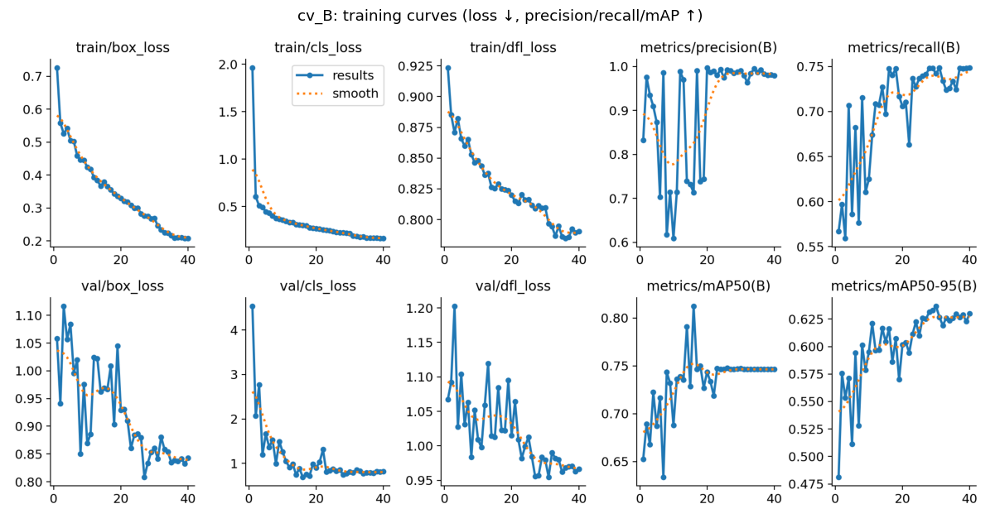


▶ final: train on all 20 S1 frames
━━ final: dataset ━━


,tiles,Keys,Wallet,Mug,Phone,Water bottle
train,981,371,197,333,384,348
val,57,7,4,8,4,5


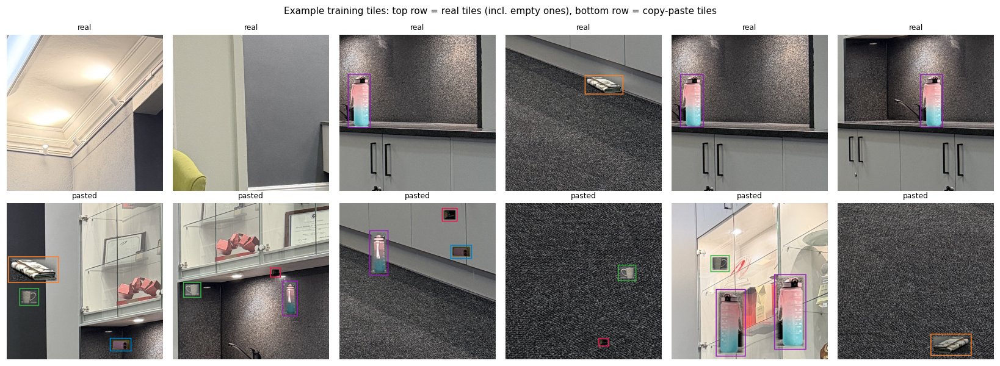

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/pf_work/datasets/final/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.5, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final, nbs=64, nms=None, opset=None, optimize=Fa

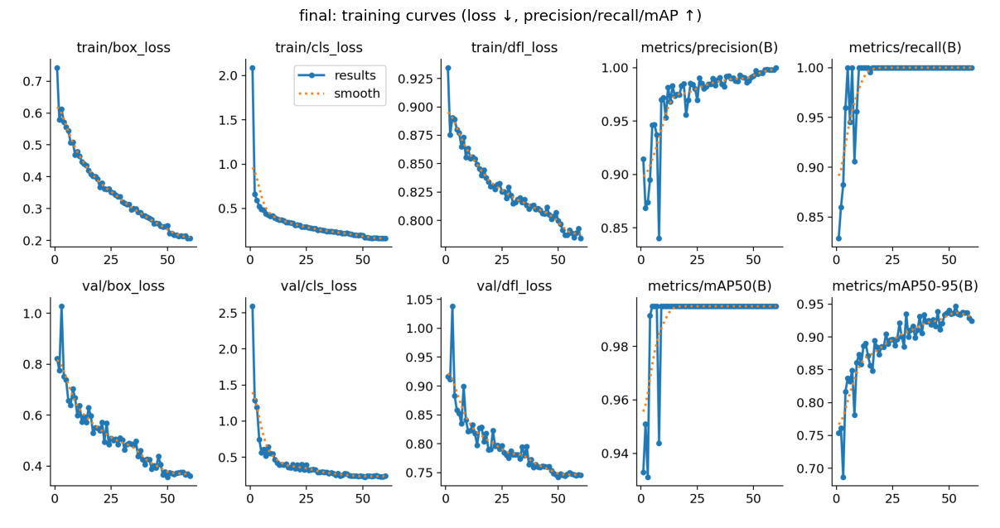

In [ ]:
BASE_WEIGHTS = "yolo11s.pt"     # 'yolo11n.pt' = smaller and faster (phone-friendly); 'yolo11s.pt' = more accurate
EPOCHS_CV    = 40
EPOCHS_FINAL = 60
BATCH        = 16
RETRAIN      = False            # True = ignore saved weights and train again
DO_CV        = True             # False = skip cross-validation (about 15 min faster); τ then defaults to 0.35
RUNS = WORK / "runs"

def train_detector(name, train_frames, val_frames, epochs):
    out = CACHE / "models" / f"{name}.pt"
    meta = CACHE / "models" / f"{name}.json"
    spec = dict(train=[int(f) for f in train_frames], base=BASE_WEIGHTS, epochs=epochs, tile=TILE,
                n_synth=N_SYNTH, zones=ZONES)
    if out.exists() and meta.exists() and not RETRAIN and json.load(open(meta)) == json.loads(json.dumps(spec)):
        print(f"✓ {name}: using saved weights {out.name}")
        return out
    t0 = time.time()
    yaml, summary = build_dataset(name, train_frames, val_frames)
    print(f"━━ {name}: dataset ━━"); display(summary.T)
    if name == "final":
        show_tiles(yaml)
    model = YOLO(BASE_WEIGHTS)
    model.train(data=str(yaml), epochs=epochs, imgsz=TILE, batch=BATCH, device=DEVICE, project=str(RUNS), name=name,
                exist_ok=True, seed=0, workers=2, verbose=False, plots=True, cos_lr=True, patience=epochs,
                hsv_h=0.015, hsv_s=0.6, hsv_v=0.5, degrees=0.0, translate=0.1, scale=0.4, fliplr=0.5,
                mosaic=1.0, close_mosaic=10, mixup=0.0)
    shutil.copy(RUNS / name / "weights" / "last.pt", out)
    json.dump(spec, open(meta, "w"))
    print(f"✓ {name}: trained in {(time.time() - t0) / 60:.1f} min → {out}")
    res_png = RUNS / name / "results.png"
    if res_png.exists():
        plt.figure(figsize=(14, 7)); plt.imshow(Image.open(res_png)); plt.axis("off")
        plt.title(f"{name}: training curves (loss ↓, precision/recall/mAP ↑)"); plt.show()
    return out

s1_frames = SESS["s1"]["frames"].frame.tolist()
half = len(s1_frames) // 2
FOLDS = {"cv_A": (s1_frames[:half], s1_frames[half:]),
         "cv_B": (s1_frames[half:], s1_frames[:half])} if DO_CV else {}

WEIGHTS = {}
for name, (tr, te) in FOLDS.items():
    print(f"\n▶ {name}: train on S1 frames {tr[0]}–{tr[-1]}, test on {te[0]}–{te[-1]}")
    WEIGHTS[name] = train_detector(name, tr, te, EPOCHS_CV)

print(f"\n▶ final: train on all {len(s1_frames)} S1 frames")
val_small = s1_frames[::max(1, len(s1_frames) // 4)]       # only for Ultralytics' progress numbers
WEIGHTS["final"] = train_detector("final", s1_frames, val_small, EPOCHS_FINAL)

---
## 9. Run the detector on whole frames
1. Cut the frame into the same 640 px tiles and detect objects in every tile (GPU, batched).
2. Put the boxes back into full-frame coordinates. Boxes cut by a tile edge are dropped, because the overlap guarantees that the object also appears whole in a neighbouring tile.
3. Detect **people** with a standard pretrained YOLO. People are blurred in displays, and objects inside a person's box are ignored (being carried).
4. Each object exists once, so we keep **the most confident box per object** and give it a zone.

Detections are cached in Drive, so this is slow only once.

In [ ]:
PRED_CONF = 0.05

def nms(boxes, scores, thr=0.5):
    boxes = np.asarray(boxes, float); order = np.argsort(-np.asarray(scores)); keep = []
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    while order.size:
        i = order[0]; keep.append(i); rest = order[1:]
        iw = np.clip(np.minimum(boxes[i, 2], boxes[rest, 2]) - np.maximum(boxes[i, 0], boxes[rest, 0]), 0, None)
        ih = np.clip(np.minimum(boxes[i, 3], boxes[rest, 3]) - np.maximum(boxes[i, 1], boxes[rest, 1]), 0, None)
        inter = iw * ih
        order = rest[inter / (area[i] + area[rest] - inter + 1e-9) <= thr]
    return keep

def detect_objects(model, img):
    arr = np.asarray(img); H, W = arr.shape[:2]
    origins = tile_origins(W, H)
    dets = []
    for i in range(0, len(origins), 32):
        chunk = origins[i:i + 32]
        tiles = [np.ascontiguousarray(arr[y:y + TILE, x:x + TILE, ::-1]) for x, y in chunk]   # BGR for Ultralytics
        res = model.predict(tiles, imgsz=TILE, conf=PRED_CONF, iou=0.5, device=DEVICE, verbose=False)
        for (x0, y0), r in zip(chunk, res):
            if r.boxes is None or len(r.boxes) == 0:
                continue
            xyxy = r.boxes.xyxy.cpu().numpy(); cf = r.boxes.conf.cpu().numpy(); cl = r.boxes.cls.cpu().numpy().astype(int)
            for (a, b, c, d), s, k in zip(xyxy, cf, cl):
                cut = (a < 2 and x0 > 0) or (b < 2 and y0 > 0) or (c > TILE - 2 and x0 + TILE < W) or (d > TILE - 2 and y0 + TILE < H)
                if not cut:
                    dets.append((OBJECTS[int(k)], float(s), float(a + x0), float(b + y0), float(c + x0), float(d + y0)))
    out = []
    for lab in OBJECTS:
        g = [d for d in dets if d[0] == lab]
        if g:
            keep = nms([d[2:] for d in g], [d[1] for d in g])
            out += [g[i] for i in keep]
    return sorted(out, key=lambda d: -d[1])

_person_model = None
def detect_people(img):
    global _person_model
    if _person_model is None:
        _person_model = YOLO("yolo11n.pt")                         # pretrained on COCO; class 0 = person
    s = 1280 / max(img.size)
    small = img.resize((round(img.width * s), round(img.height * s)))
    r = _person_model.predict(np.ascontiguousarray(np.asarray(small)[:, :, ::-1]), imgsz=1280, conf=0.35,
                              classes=[0], device=DEVICE, verbose=False)[0]
    if r.boxes is None or len(r.boxes) == 0:
        return []
    return [[float(v) / s for v in b] for b in r.boxes.xyxy.cpu().numpy()]

_models = {}
def get_model(name):
    if name not in _models:
        _models[name] = YOLO(str(WEIGHTS[name]))
    return _models[name]

def run_detection(model_name, sk, frames):
    """Detections for the given frames, cached in Drive. Returns {frame: {'objects': [...], 'people': [...]}}."""
    wsha = hashlib.sha1(open(WEIGHTS[model_name], "rb").read()).hexdigest()[:8]
    path = CACHE / "detections" / f"{model_name}_{wsha}_{sk}.json"
    try:
        cache = {int(k): v for k, v in json.load(open(path)).items()} if path.exists() else {}
    except Exception:          # half-written file from a crash → start this cache again
        cache = {}
    todo = [f for f in frames if f not in cache]
    if todo:
        model = get_model(model_name); t0 = time.time()
        for i, f in enumerate(todo):
            img = open_frame(sk, f)
            people = PERSON_BOXES.get((sk, f)) or detect_people(img)
            cache[f] = dict(objects=detect_objects(model, img),
                            people=[[float(v) for v in b] for b in people])
            if (i + 1) % 10 == 0 or i + 1 == len(todo):
                print(f"   {model_name} on {sk.upper()}: {i + 1}/{len(todo)} frames  ({(time.time() - t0) / (i + 1):.2f} s/frame)")
        with open(path, "w") as fh:
            json.dump({str(k): v for k, v in cache.items()}, fh, default=float)
    for f in frames:
        PERSON_BOXES.setdefault((sk, f), cache[f]["people"])
    return {f: cache[f] for f in frames}

def sightings(dets, sk, tau):
    """One row per (frame, object): best box not held by a person, its zone, and whether conf ≥ τ."""
    fr = SESS[sk]["frames"].set_index("frame"); rows = []
    for f, d in dets.items():
        people = d["people"]
        for obj in OBJECTS:
            cand = [x for x in d["objects"] if x[0] == obj and overlap_frac(x[2:], people) < PERSON_OVERLAP]
            if cand:
                lab, conf, *box = cand[0]
                rows.append(dict(frame=f, time=fr.loc[f, "time"], object=obj, conf=conf, box=tuple(box),
                                 zone=zone_of_box(*box, fr.loc[f, "W"], fr.loc[f, "H"])))
            else:
                rows.append(dict(frame=f, time=fr.loc[f, "time"], object=obj, conf=0.0, box=None, zone=None))
    df = pd.DataFrame(rows).sort_values(["object", "frame"]).reset_index(drop=True)
    df["sighted"] = df.conf >= tau
    return df

DETS = {}
for name, (tr, te) in FOLDS.items():
    print(f"▶ {name} on its held-out S1 frames")
    DETS[name] = run_detection(name, "s1", te)
OOF = {}
for name in FOLDS:
    OOF.update(DETS[name])            # out-of-fold detections for every S1 frame

▶ cv_A on its held-out S1 frames
   cv_A on S1: 10/10 frames  (1.62 s/frame)
▶ cv_B on its held-out S1 frames
   cv_B on S1: 10/10 frames  (1.40 s/frame)


---
## 10. Choose the threshold τ on Session 1 and freeze it
**Rule, fixed in advance:** one global τ that maximises **balanced accuracy** over S1 (frame, object) pairs, using out-of-fold detections only.
* A **present** pair (object visible) is correct only if it is sighted (conf ≥ τ) **in the right zone**.
* An **absent** pair (object not visible) is correct if it is **not** sighted.
* Frames with a person holding or blocking the object are left out. If several τ values tie, the **highest** is taken.

The result is written to `frozen_config.json`. Session 2 is evaluated only with this frozen τ.

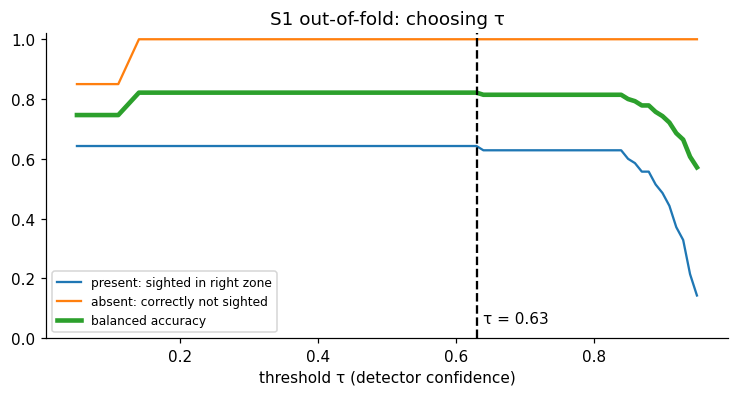

,tau,present_correct,absent_correct,balanced_acc,zone_acc_when_detected,n_present,n_absent
58,0.63,0.643,1.0,0.821,1.0,70,20


🔒 Frozen: τ = 0.63 → /content/drive/MyDrive/PauseFind_cache/frozen_config.json


In [ ]:
FORCE_REFREEZE = False
FROZEN_PATH = CACHE / "frozen_config.json"
TAUS = np.round(np.arange(0.05, 0.96, 0.01), 2)

def frame_metrics(sight, gt, tau):
    m = gt.merge(sight.drop(columns=["time"]), on=["frame", "object"], suffixes=("_gt", ""))
    m = m[m.state != "with_person"]
    pres, absn = m[m.state == "visible"], m[m.state != "visible"]
    hit = (pres.conf >= tau) & (pres.zone == pres.zone_gt)
    rej = absn.conf < tau
    det_pres = (pres.conf >= tau)
    return dict(tau=tau, present_correct=hit.mean(), absent_correct=rej.mean(),
                balanced_acc=(hit.mean() + rej.mean()) / 2,
                zone_acc_when_detected=(pres.zone[det_pres] == pres.zone_gt[det_pres]).mean() if det_pres.any() else np.nan,
                n_present=len(pres), n_absent=len(absn))

if DO_CV:
    oof_sight = sightings(OOF, "s1", 0.0)
    sweep = pd.DataFrame([frame_metrics(oof_sight, GT["s1"], t) for t in TAUS])
    best = sweep.balanced_acc.max()
    TAU_CHOSEN = float(sweep[sweep.balanced_acc >= best - 1e-12].tau.max())     # tie → highest τ
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(sweep.tau, sweep.present_correct, label="present: sighted in right zone")
    ax.plot(sweep.tau, sweep.absent_correct, label="absent: correctly not sighted")
    ax.plot(sweep.tau, sweep.balanced_acc, lw=3, label="balanced accuracy")
    ax.axvline(TAU_CHOSEN, ls="--", c="k"); ax.text(TAU_CHOSEN + 0.01, 0.05, f"τ = {TAU_CHOSEN:.2f}")
    ax.set_xlabel("threshold τ (detector confidence)"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8, loc="lower left")
    ax.set_title("S1 out-of-fold: choosing τ"); plt.show()
    display(sweep[sweep.tau == TAU_CHOSEN].round(3))
else:
    TAU_CHOSEN = 0.35
    print("Cross-validation skipped → τ = 0.35 (default, not tuned)")

spec = dict(tau=TAU_CHOSEN, model="final", weights_sha1=hashlib.sha1(open(WEIGHTS["final"], "rb").read()).hexdigest()[:12],
            base=BASE_WEIGHTS, tile=TILE, overlap=OVERLAP, person_overlap=PERSON_OVERLAP, zones=ZONES,
            frozen_at=dt.datetime.now().isoformat(timespec="seconds"))
s2_results_exist = (CACHE / "s2_results.csv").exists()
if FROZEN_PATH.exists() and not FORCE_REFREEZE:
    FROZEN = json.load(open(FROZEN_PATH))
    print(f"🔒 Using the existing freeze from {FROZEN['frozen_at']}: τ = {FROZEN['tau']}")
    if abs(FROZEN["tau"] - TAU_CHOSEN) > 1e-9 or FROZEN["weights_sha1"] != spec["weights_sha1"]:
        print("   ⚠️ The current S1 run would choose differently. Set FORCE_REFREEZE = True to replace it "
              "(only allowed before S2 results exist).")
else:
    if FORCE_REFREEZE and s2_results_exist:
        raise RuntimeError("S2 results already exist. Re-freezing now would tune on the test set. Delete s2_results.csv only if you really mean to.")
    FROZEN = spec
    json.dump(FROZEN, open(FROZEN_PATH, "w"), indent=1)
    print(f"🔒 Frozen: τ = {TAU_CHOSEN:.2f} → {FROZEN_PATH}")
TAU = FROZEN["tau"]

---
## 11. Answering a question (uses the past only)
`history(sight, obj, t)` hands the answer function **only frames ≤ t**. The answer is:
* the latest sighting is frame *t* itself → **"visible now"** in that zone;
* the latest sighting is earlier → **"last seen"** in that zone, *until* that frame's time;
* no sighting yet → **"not seen"**.

A check scrambles every future frame and confirms that no answer changes.

In [ ]:
def history(sight, obj, t):
    return sight[(sight.object == obj) & (sight.frame <= t)].sort_values("frame")

def answer(hist):
    seen = hist[hist.sighted]
    if seen.empty:
        return dict(state="not_seen", zone=None, frame=None, time=None, conf=None, box=None)
    last = seen.iloc[-1]
    return dict(state="visible" if last.frame == hist.frame.max() else "last_seen", zone=last.zone,
                frame=int(last.frame), time=last.time, conf=float(last.conf), box=last.box)

def fmt_time(t):
    if t is None or pd.isna(t):
        return "an earlier photo"
    return f"{t.hour % 12 or 12}:{t.minute:02d} {'am' if t.hour < 12 else 'pm'}"

def sentence(obj, a):
    o = f"your {obj.lower()}"
    if a["state"] == "visible":
        return f"{o.capitalize()} {'are' if obj == 'Keys' else 'is'} {SPOKEN[a['zone']]}, seen just now at {fmt_time(a['time'])}."
    if a["state"] == "last_seen":
        return f"{o.capitalize()} {'were' if obj == 'Keys' else 'was'} {SPOKEN[a['zone']]} until {fmt_time(a['time'])}. Not seen since."
    return f"I have not seen {o} yet."

def answer_queries(q, sight):
    rows = []
    for r in q.itertuples():
        a = answer(history(sight, r.object, r.t))
        rows.append(dict(qid=r.qid, sys_state=a["state"], sys_zone=a["zone"], sys_frame=a["frame"], sys_conf=a["conf"]))
    return q.merge(pd.DataFrame(rows), on="qid")

def no_future_check(q, sight, seed=0):
    rng = np.random.default_rng(seed); ok = 0
    base = answer_queries(q, sight)
    for r in q.itertuples():
        s = sight.copy(); fut = s.frame > r.t
        s.loc[fut, "sighted"] = rng.random(fut.sum()) < 0.5
        s.loc[fut, "zone"] = rng.choice(ZONE_NAMES, fut.sum())
        a = answer(history(s, r.object, r.t)); b = base[base.qid == r.qid].iloc[0]
        bz = b.sys_zone if isinstance(b.sys_zone, str) else None
        ok += (a["state"] == b.sys_state) and (a["zone"] == bz)
    return ok, len(q)

def score(ans):
    a = ans.copy()
    exp_has_zone = a.exp_state != "not_seen"
    a["zone_ok"] = np.where(exp_has_zone, (a.sys_state != "not_seen") & (a.sys_zone == a.exp_zone), a.sys_state == "not_seen")
    a["state_ok"] = a.sys_state == a.exp_state
    a["time_ok"] = np.where(a.exp_state == "last_seen",
                            (a.sys_state == "last_seen") & ((a.sys_frame.fillna(-99) - a.exp_frame.fillna(-999)).abs() <= 1),
                            a.state_ok)
    a["all_ok"] = a.zone_ok & a.state_ok & a.time_ok
    return a

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return p, max(0, c - h), min(1, c + h)

def baselines(q):
    b = q.copy()
    prior = b.assign(sys_state="visible", sys_zone=b.object.map(USUAL_ZONE), sys_frame=b.t, sys_conf=None)
    rnd_expected = (b.exp_state != "not_seen").mean() / len(ZONE_NAMES)
    return score(prior), rnd_expected

def report(ans, label):
    s = score(ans); prior, rnd = baselines(ans[list(QUERIES[ans.session.iloc[0]].columns)])
    n = len(s)
    rows = [("Random zone (1 in 8)", rnd * n, n), ("Prior: usual S1 zone", prior.zone_ok.sum(), n),
            ("Ours: tiled YOLO + last-seen", s.zone_ok.sum(), n)]
    tab = pd.DataFrame([dict(system=nm, zone_accuracy=k / n, ci95_low=wilson(k, n)[1], ci95_high=wilson(k, n)[2], n=n)
                        for nm, k, n in rows]).set_index("system")
    display(Markdown(f"#### {label}: zone accuracy over {n} questions"))
    display(tab.style.format({"zone_accuracy": "{:.0%}", "ci95_low": "{:.0%}", "ci95_high": "{:.0%}"}))
    more = pd.DataFrame({"zone right": s.groupby("object").zone_ok.mean(),
                         "state right (now / earlier / never)": s.groupby("object").state_ok.mean(),
                         "fully right (zone+state+time ±1 frame)": s.groupby("object").all_ok.mean(),
                         "questions": s.groupby("object").size()})
    more.loc["ALL"] = [s.zone_ok.mean(), s.state_ok.mean(), s.all_ok.mean(), len(s)]
    display(more.style.format({c: "{:.0%}" for c in more.columns[:3]}))
    return s, tab

def plot_results(s, tab, label):
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[1, 2.4]))
    ax = axs[0]
    cols = ["#bbbbbb", "#8fa8c8", "#1f5fa8"]
    ax.bar(range(3), tab.zone_accuracy, color=cols,
           yerr=[tab.zone_accuracy - tab.ci95_low, tab.ci95_high - tab.zone_accuracy], capsize=5)
    ax.set_xticks(range(3)); ax.set_xticklabels(["Random", "Prior", "Ours"]); ax.set_ylim(0, 1.05)
    for i, v in enumerate(tab.zone_accuracy):
        ax.text(i, v + 0.03, f"{v:.0%}", ha="center", fontsize=10)
    ax.set_ylabel("zone accuracy"); ax.set_title(f"{label}: overall")
    ax = axs[1]
    zs = [z for z in ZONE_NAMES] + ["not seen"]
    key = s.exp_zone.fillna("not seen")
    acc = [wilson(int(s.zone_ok[key == z].sum()), int((key == z).sum())) for z in zs]
    ns = [int((key == z).sum()) for z in zs]
    x = np.arange(len(zs)); p = np.array([a[0] for a in acc])
    ax.bar(x, np.nan_to_num(p), color="#1f5fa8",
           yerr=[np.nan_to_num(p - [a[1] for a in acc]), np.nan_to_num(np.array([a[2] for a in acc]) - p)], capsize=4)
    ax.axhline(1 / 8, ls="--", c="grey"); ax.text(len(zs) - 0.5, 1 / 8 + 0.02, "guessing (1 in 8)", ha="right", fontsize=8, color="grey")
    ax.set_xticks(x); ax.set_xticklabels([f"{i + 1}\n{z.replace(' ', chr(10), 1)}\n(n={n})" if z != "not seen" else f"–\nnot seen\n(n={n})"
                                          for i, (z, n) in enumerate(zip(zs, ns))], fontsize=7)
    ax.set_ylim(0, 1.05); ax.set_ylabel("% right zone"); ax.set_title("Named the right zone, by the zone where the object really was")
    plt.tight_layout(); plt.show()

### 11.1 Session 1 results (out-of-fold): an early idea, not the test
Each S1 frame is answered by the cross-validation model that **did not train on it**. Frames 11–20 are seen by a model trained on frames 1–10 (and the reverse), so objects in new places are a real test. There are only 20 frames, though, so the error bars are wide.

Frame level (S1 out-of-fold, τ=0.63): present pairs found in the right zone 64% (n=70), absent pairs correctly empty 100% (n=20), balanced accuracy 82%
No-future check: 50/50 answers unchanged when all later frames are scrambled ✓


#### Session 1 (out-of-fold): zone accuracy over 50 questions

,zone_accuracy,ci95_low,ci95_high,n
system,,,,
Random zone (1 in 8),10%,5%,22%,50
Prior: usual S1 zone,62%,48%,74%,50
Ours: tiled YOLO + last-seen,74%,60%,84%,50


,zone right,state right (now / earlier / never),fully right (zone+state+time ±1 frame),questions
object,,,,
Keys,0%,0%,0%,10.000000
Mug,100%,100%,100%,10.000000
Phone,100%,100%,100%,10.000000
Wallet,70%,70%,70%,10.000000
Water bottle,100%,100%,100%,10.000000
ALL,74%,74%,74%,50.000000


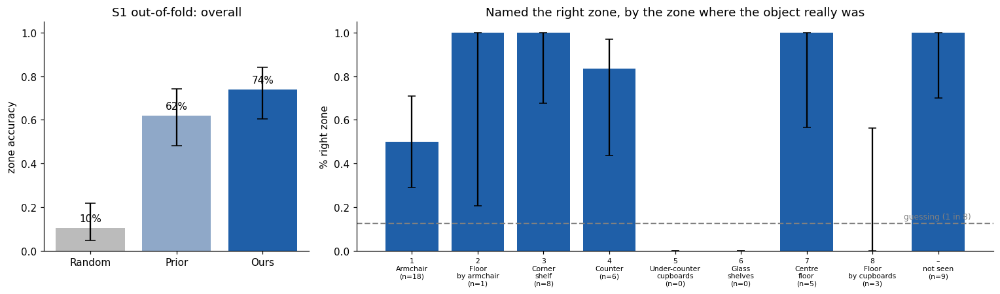

In [ ]:
if DO_CV:
    s1_sight = sightings(OOF, "s1", TAU)
    m = frame_metrics(s1_sight, GT["s1"], TAU)
    print(f"Frame level (S1 out-of-fold, τ={TAU}): present pairs found in the right zone {m['present_correct']:.0%} "
          f"(n={m['n_present']}), absent pairs correctly empty {m['absent_correct']:.0%} (n={m['n_absent']}), "
          f"balanced accuracy {m['balanced_acc']:.0%}")
    ok, n = no_future_check(QUERIES["s1"], s1_sight)
    print(f"No-future check: {ok}/{n} answers unchanged when all later frames are scrambled {'✓' if ok == n else '❌'}")
    S1_SCORED, S1_TAB = report(answer_queries(QUERIES["s1"], s1_sight), "Session 1 (out-of-fold)")
    plot_results(S1_SCORED, S1_TAB, "S1 out-of-fold")

---
## 12. Session 2: the test
Order enforced in code: **frozen config ✓ → questions saved ✓ → detect on S2 photos → score**.

   final on S2: 10/60 frames  (1.35 s/frame)
   final on S2: 20/60 frames  (1.32 s/frame)
   final on S2: 30/60 frames  (1.31 s/frame)
   final on S2: 40/60 frames  (1.30 s/frame)
   final on S2: 50/60 frames  (1.30 s/frame)
   final on S2: 60/60 frames  (1.29 s/frame)
Detection done (78 s incl. cache).
Frame level (S2, τ=0.63): present pairs found in the right zone 34% (n=220), absent pairs correctly empty 100% (n=51), balanced accuracy 67%
No-future check: 50/50 answers unchanged ✓


#### Session 2 (TEST): zone accuracy over 50 questions

,zone_accuracy,ci95_low,ci95_high,n
system,,,,
Random zone (1 in 8),12%,6%,24%,50
Prior: usual S1 zone,12%,6%,24%,50
Ours: tiled YOLO + last-seen,48%,35%,61%,50


,zone right,state right (now / earlier / never),fully right (zone+state+time ±1 frame),questions
object,,,,
Keys,0%,0%,0%,10.000000
Mug,90%,50%,50%,10.000000
Phone,60%,40%,40%,10.000000
Wallet,0%,0%,0%,10.000000
Water bottle,90%,80%,80%,10.000000
ALL,48%,34%,34%,50.000000


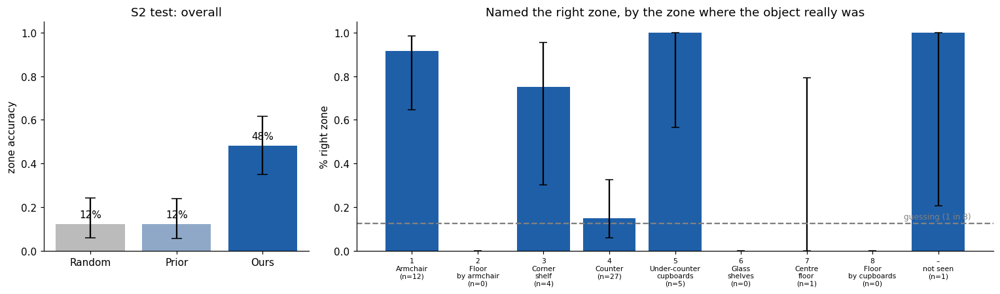

saved → /content/drive/MyDrive/PauseFind_cache/s2_results.csv


In [ ]:
S2_SCORED = None
if "s2" not in SESS:
    print("No Session 2 photos found. Add them to Drive (section 2) and run again.")
else:
    assert FROZEN_PATH.exists(), "freeze first (section 10)"
    have_q = "s2" in QUERIES and (CACHE / "queries_S2.csv").exists()
    if not have_q:
        print("⚠️ Session 2 has no ground truth (no Roboflow labels, no readable log), so it cannot be scored. "
              "The detector still runs, for the demo.")
    t0 = time.time()
    DETS["s2"] = run_detection("final", "s2", SESS["s2"]["frames"].frame.tolist())
    s2_sight = sightings(DETS["s2"], "s2", TAU)
    print(f"Detection done ({time.time() - t0:.0f} s incl. cache).")
    if have_q:
        m = frame_metrics(s2_sight, GT["s2"], TAU)
        print(f"Frame level (S2, τ={TAU}): present pairs found in the right zone {m['present_correct']:.0%} "
              f"(n={m['n_present']}), absent pairs correctly empty {m['absent_correct']:.0%} (n={m['n_absent']}), "
              f"balanced accuracy {m['balanced_acc']:.0%}")
        ok, n = no_future_check(QUERIES["s2"], s2_sight)
        print(f"No-future check: {ok}/{n} answers unchanged {'✓' if ok == n else '❌'}")
        S2_SCORED, S2_TAB = report(answer_queries(QUERIES["s2"], s2_sight), "Session 2 (TEST)")
        plot_results(S2_SCORED, S2_TAB, "S2 test")
        S2_SCORED.to_csv(CACHE / "s2_results.csv", index=False)
        print(f"saved → {CACHE / 's2_results.csv'}")

### 12.1 Where does it go wrong?
* **Zone confusion** at frame level: rows show the true zone and columns the zone the system named (*missed* = not sighted).
* **Failure gallery:** wrong answers, showing the true box (green) and the system's box (red).

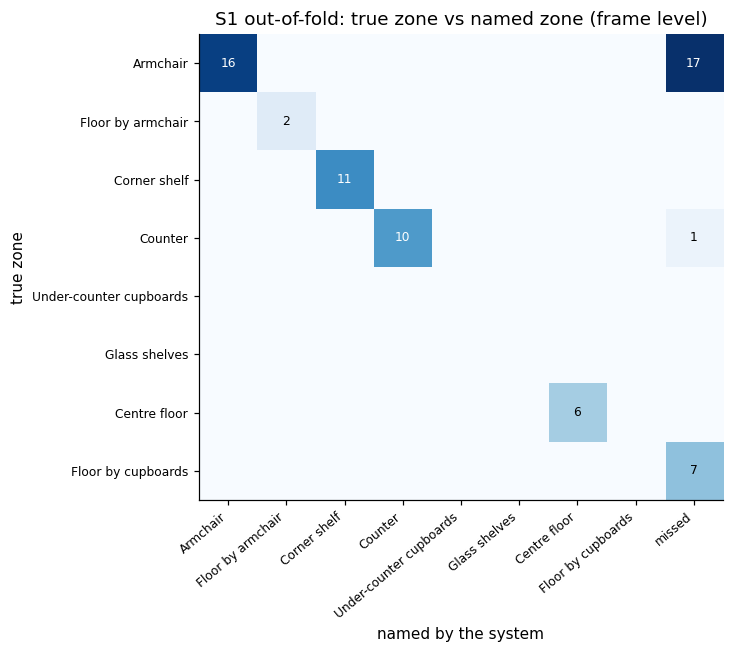

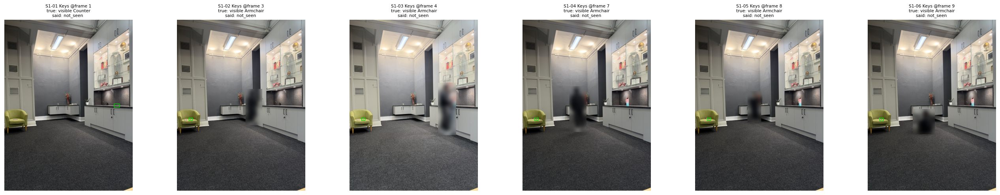

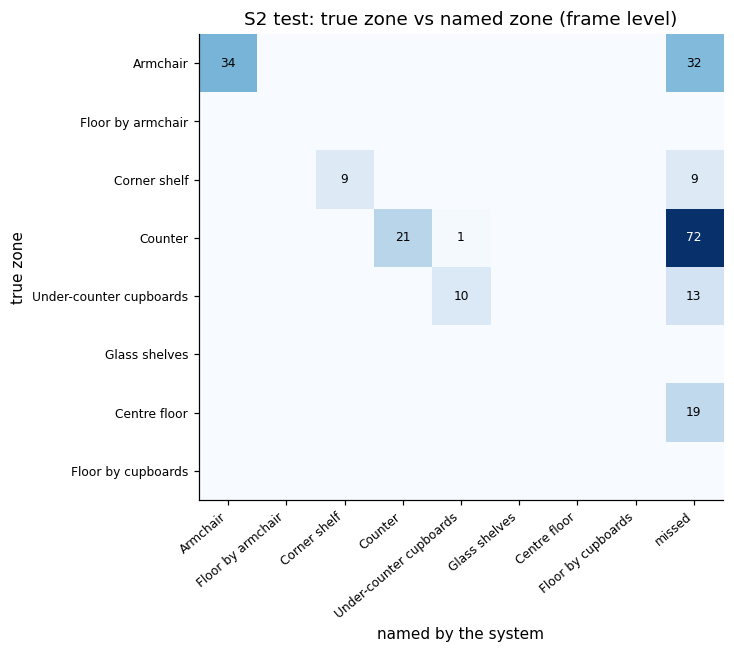

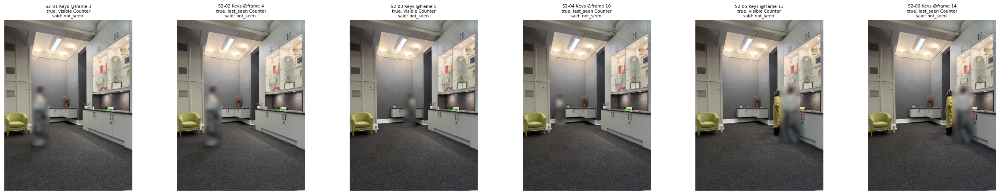

In [ ]:
def zone_confusion(sight, gt, title):
    m = gt.merge(sight.drop(columns=["time"]), on=["frame", "object"], suffixes=("_gt", ""))
    m = m[m.state == "visible"]
    pred = np.where(m.sighted, m.zone.fillna("missed"), "missed")
    cm = pd.crosstab(pd.Categorical(m.zone_gt, ZONE_NAMES), pd.Categorical(pred, ZONE_NAMES + ["missed"]), dropna=False)
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.imshow(cm.values, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm.values[i, j]:
                ax.text(j, i, cm.values[i, j], ha="center", va="center", fontsize=8,
                        color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")
    ax.set_xticks(range(cm.shape[1])); ax.set_xticklabels(cm.columns, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(cm.shape[0])); ax.set_yticklabels(cm.index, fontsize=8)
    ax.set_xlabel("named by the system"); ax.set_ylabel("true zone"); ax.set_title(title); plt.show()

def failure_gallery(scored, sight, sk, n=6):
    bad = scored[~scored.zone_ok].head(n)
    if bad.empty:
        print("No wrong zone answers 🎉"); return
    fig, axs = plt.subplots(1, len(bad), figsize=(4 * len(bad), 4.6))
    axs = np.atleast_1d(axs)
    gt = GT[sk]
    for ax, r in zip(axs, bad.itertuples()):
        f = int(r.sys_frame) if pd.notna(r.sys_frame) else int(r.exp_frame) if pd.notna(r.exp_frame) else r.t
        img, s = small_frame(sk, f, 1600); img = blur_regions(img, PERSON_BOXES.get((sk, f), []), s)
        items = []
        g = gt[(gt.frame == (int(r.exp_frame) if pd.notna(r.exp_frame) else f)) & (gt.object == r.object)]
        if len(g) and g.iloc[0].box is not None:
            x1, y1, x2, y2 = g.iloc[0].box; items.append(("truth", x1, y1, x2, y2, ""))
        p = sight[(sight.frame == f) & (sight.object == r.object)]
        if len(p) and p.iloc[0].box is not None:
            x1, y1, x2, y2 = p.iloc[0].box; items.append(("pred", x1, y1, x2, y2, ""))
        OBJ_COLORS.update({"truth": (0, 220, 0), "pred": (255, 0, 0)})
        draw_boxes(img, items, s, width=5)
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"{r.qid} {r.object} @frame {r.t}\ntrue: {r.exp_state} {r.exp_zone or ''}\nsaid: {r.sys_state} {r.sys_zone or ''}",
                     fontsize=7)
    plt.tight_layout(); plt.show()

if DO_CV:
    zone_confusion(s1_sight, GT["s1"], "S1 out-of-fold: true zone vs named zone (frame level)")
    failure_gallery(S1_SCORED, s1_sight, "s1")
if S2_SCORED is not None:
    zone_confusion(s2_sight, GT["s2"], "S2 test: true zone vs named zone (frame level)")
    failure_gallery(S2_SCORED, s2_sight, "s2")

---
## 13. 🎙️ Demo: *"Where is my …?"*
Pick an object and the moment of the question (a frame), then press **Where is it?**. The notebook speaks the answer and shows the frame and the crop it is based on, with people blurred.
Speech uses gTTS (needs internet) and falls back to the browser's voice. If the buttons don't respond, use the next cell (13.1) instead.

In [ ]:
DEMO_SESSION = "s2" if "s2" in DETS else "s1"
if DEMO_SESSION == "s1":
    DETS["s1_final"] = run_detection("final", "s1", s1_frames)
    DEMO_SIGHT = sightings(DETS["s1_final"], "s1", TAU)
    print("ℹ️ Demo on Session 1 with the final model (it was trained on these frames, so it looks better than it really is).")
else:
    DEMO_SIGHT = s2_sight

def speak(text):
    try:
        from gtts import gTTS
        buf = io.BytesIO(); gTTS(text, lang="en").write_to_fp(buf)
        display(Audio(buf.getvalue(), autoplay=True))
    except Exception:
        display(Javascript(f"window.speechSynthesis.speak(new SpeechSynthesisUtterance({json.dumps(text)}));"))

def ask(obj, t, sk=DEMO_SESSION, sight=None, say=True):
    sight = DEMO_SIGHT if sight is None else sight
    a = answer(history(sight, obj, t))
    text = sentence(obj, a)
    display(Markdown(f"### 🗣️ “{text}”"))
    if sk in GT:
        st, z, lf = expected_answer(GT[sk][(GT[sk].object == obj) & (GT[sk].frame <= t)].sort_values("frame"))
        tick = "✅" if (st == a["state"] and z == a["zone"]) else "❌"
        display(Markdown(f"<small>ground truth: {st} {z or ''} {'(frame ' + str(lf) + ')' if lf else ''} {tick}</small>"))
    if say:
        speak(text)
    f = a["frame"] if a["frame"] is not None else t
    fig, axs = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw=dict(width_ratios=[1.3, 1]))
    items = []
    if a["box"] is not None:
        x1, y1, x2, y2 = a["box"]; items = [(obj, x1, y1, x2, y2, f"{obj} {a['conf']:.2f}")]
    show_frame(sk, f, extra=items, with_gt=False, zones=True, ax=axs[0],
               title=f"evidence: frame {f}" + (f" ({fmt_time(a['time'])})" if a['time'] is not None else ""))
    if a["box"] is not None:
        img = open_frame(sk, f); x1, y1, x2, y2 = a["box"]; pad = 3 * max(x2 - x1, y2 - y1)
        crop = img.crop((max(0, x1 - pad), max(0, y1 - pad), min(img.width, x2 + pad), min(img.height, y2 + pad)))
        crop = blur_regions(crop, [(b[0] - max(0, x1 - pad), b[1] - max(0, y1 - pad), b[2] - max(0, x1 - pad), b[3] - max(0, y1 - pad))
                                   for b in PERSON_BOXES.get((sk, f), [])])
        d = ImageDraw.Draw(crop); ox, oy = max(0, x1 - pad), max(0, y1 - pad)
        d.rectangle([x1 - ox - 4, y1 - oy - 4, x2 - ox + 4, y2 - oy + 4], outline=OBJ_COLORS[obj], width=3)
        axs[1].imshow(crop); axs[1].set_title(f"zoom: {a['zone']}", fontsize=9)
    else:
        axs[1].text(0.5, 0.5, "no sighting yet", ha="center", va="center", fontsize=14)
    axs[1].axis("off"); plt.tight_layout(); plt.show()
    return a

try:
    import ipywidgets as W
    frames_demo = SESS[DEMO_SESSION]["frames"]
    w_obj = W.Dropdown(options=OBJECTS, value="Keys", description="Object")
    w_t = W.SelectionSlider(options=[(f"#{r.frame} {fmt_time(r.time)}", int(r.frame)) for r in frames_demo.itertuples()],
                            value=int(frames_demo.frame.iloc[-1]), description="Asked at", layout=W.Layout(width="70%"))
    w_btn = W.Button(description="Where is it?", button_style="primary", icon="search")
    w_out = W.Output()
    def _go(_):
        w_out.clear_output()
        with w_out:
            ask(w_obj.value, w_t.value)
    w_btn.on_click(_go)
    display(W.VBox([W.HBox([w_obj, w_btn]), w_t, w_out]))
except Exception as e:
    print("Widgets unavailable here, use the next cell.", e)

### 13.1 Demo without widgets
Edit the object and frame, then run the cell.

### 🗣️ “I have not seen your keys yet.”

<small>ground truth: last_seen Counter (frame 25) ❌</small>

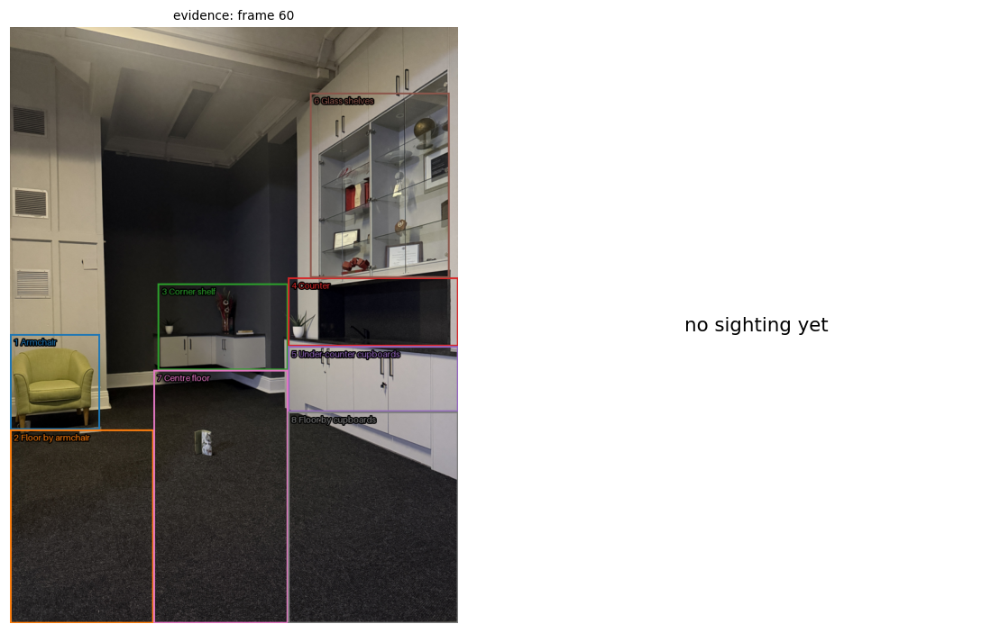

In [ ]:
OBJECT = "Keys"                                           # Keys / Wallet / Mug / Phone / Water bottle
ASK_AT = int(SESS[DEMO_SESSION]["frames"].frame.iloc[-1])  # frame number when the question is asked
_ = ask(OBJECT, ASK_AT)

---
## 14. Does it fit a low-resource device? (CPU timing)
Times the final detector on the **CPU** (no GPU), as a stand-in for an offline phone.
A phone-friendly option is `BASE_WEIGHTS = "yolo11n.pt"` (2.6 M parameters). Ultralytics can also export to TFLite or ONNX for Android (`model.export(format="tflite")`); that was not run here.

In [ ]:
cpu_model = YOLO(str(WEIGHTS["final"]))
img = open_frame(DEMO_SESSION, int(SESS[DEMO_SESSION]["frames"].frame.iloc[0]))
_dev, _gpu = DEVICE, GPU
DEVICE, GPU = "cpu", False
try:
    detect_objects(cpu_model, img)                          # warm-up
    t0 = time.time(); n_rep = 2
    for _ in range(n_rep):
        detect_objects(cpu_model, img)
    per_frame = (time.time() - t0) / n_rep
finally:
    DEVICE, GPU = _dev, _gpu
n_tiles = len(tile_origins(*img.size))
n_params = sum(p.numel() for p in cpu_model.model.parameters()) / 1e6
print(f"Model {BASE_WEIGHTS} fine-tuned: {n_params:.1f} M parameters")
print(f"CPU: {per_frame:.2f} s per frame ({n_tiles} tiles of {TILE} px; {per_frame / n_tiles * 1000:.0f} ms per tile), "
      f"{os.cpu_count()} CPU cores")
print(f"→ a photo every 30 s leaves {'plenty of' if per_frame < 10 else 'little'} time per frame.")

Model yolo11s.pt fine-tuned: 9.4 M parameters
CPU: 25.72 s per frame (70 tiles of 640 px; 367 ms per tile), 2 CPU cores
→ a photo every 30 s leaves little time per frame.


---
## 15. Summary for the write-up

In [ ]:
summary = {"threshold τ (frozen on S1)": TAU, "detector": f"{BASE_WEIGHTS} fine-tuned on S1 tiles + copy-paste",
           "S1 frames": len(s1_frames), "S1 ground truth": GT_SOURCE.get("s1")}
if DO_CV:
    summary.update({"S1 out-of-fold zone accuracy (ours)": f"{S1_SCORED.zone_ok.mean():.0%} (n={len(S1_SCORED)})",
                    "S1 out-of-fold zone accuracy (prior)": f"{S1_TAB.zone_accuracy.iloc[1]:.0%}"})
if S2_SCORED is not None:
    p, lo, hi = wilson(int(S2_SCORED.zone_ok.sum()), len(S2_SCORED))
    summary.update({"S2 ground truth": GT_SOURCE.get("s2"),
                    "S2 TEST zone accuracy (ours)": f"{p:.0%}  [95% CI {lo:.0%}–{hi:.0%}]  (n={len(S2_SCORED)})",
                    "S2 zone accuracy, prior baseline": f"{S2_TAB.zone_accuracy.iloc[1]:.0%}",
                    "S2 zone accuracy, random baseline": f"{S2_TAB.zone_accuracy.iloc[0]:.0%}",
                    "S2 state right (now / earlier / never)": f"{S2_SCORED.state_ok.mean():.0%}",
                    "S2 fully right (zone + state + time ±1 frame)": f"{S2_SCORED.all_ok.mean():.0%}"})
summary["CPU seconds per frame"] = round(per_frame, 2)
display(pd.Series(summary, name="value").to_frame())
json.dump({k: str(v) for k, v in summary.items()}, open(CACHE / "summary.json", "w"), indent=1)
print(f"saved → {CACHE / 'summary.json'}")

,value
threshold τ (frozen on S1),0.63
detector,yolo11s.pt fine-tuned on S1 tiles + copy-paste
S1 frames,20
S1 ground truth,Roboflow boxes
S1 out-of-fold zone accuracy (ours),74% (n=50)
S1 out-of-fold zone accuracy (prior),62%
S2 ground truth,Roboflow boxes
S2 TEST zone accuracy (ours),48% [95% CI 35%–61%] (n=50)
"S2 zone accuracy, prior baseline",12%
"S2 zone accuracy, random baseline",12%


saved → /content/drive/MyDrive/PauseFind_cache/summary.json


In [ ]:
# ═══ 16. EXPORT EVERYTHING FOR THE SLIDES → My Drive/PauseFind_cache/PauseFind_export(.zip) ═══
# Run once after everything above. Saves figures, demo cards + audio, a demo animation, tables and models.
import warnings; warnings.filterwarnings("ignore")
EXP = CACHE / "PauseFind_export"
shutil.rmtree(EXP, ignore_errors=True)
for d in ["1_figures", "2_demo_cards", "3_demo_audio", "4_tables", "5_training_runs", "6_models"]:
    (EXP / d).mkdir(parents=True, exist_ok=True)
done = []

def _save(fig, name):
    fig.savefig(EXP / "1_figures" / name, dpi=150, bbox_inches="tight"); plt.close(fig); done.append(name)

def _capture(name, fn, *args):
    """Run a plotting function from the notebook and save the figure it shows."""
    _orig = plt.show
    plt.show = lambda *a, **k: _save(plt.gcf(), name)
    try:
        fn(*args)
    except Exception as e:
        print(f"⚠️ {name}: {e}")
    finally:
        plt.show = _orig

# ── 1. Figures ───────────────────────────────────────────────────────────────────────
fig, axs = plt.subplots(1, 3 if "s2" in SESS else 2, figsize=(16, 8))
show_frame("s1", SESS["s1"]["frames"].frame.iloc[0], zones=True, ax=axs[0], title="Session 1: the 8 zones + labelled objects")
show_frame("s1", SESS["s1"]["frames"].frame.iloc[-5], zones=True, ax=axs[1], title="Session 1, later photo")
if "s2" in SESS:
    show_frame("s2", SESS["s2"]["frames"].frame.iloc[0], zones=True, ax=axs[2], title="Session 2: same zones")
plt.tight_layout(); _save(fig, "01_zone_map.png")

if DO_CV:
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(sweep.tau, sweep.present_correct, label="present: sighted in right zone")
    ax.plot(sweep.tau, sweep.absent_correct, label="absent: correctly not sighted")
    ax.plot(sweep.tau, sweep.balanced_acc, lw=3, label="balanced accuracy")
    ax.axvline(TAU, ls="--", c="k"); ax.text(TAU + 0.01, 0.05, f"τ = {TAU:.2f}")
    ax.set_xlabel("threshold τ (detector confidence)"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8, loc="lower left")
    ax.set_title("Choosing τ on Session 1 (out-of-fold)"); _save(fig, "02_threshold_tau.png")
    _capture("03_S1_results.png", plot_results, S1_SCORED, S1_TAB, "S1 out-of-fold")
    _capture("04_S1_zone_confusion.png", zone_confusion, s1_sight, GT["s1"], "S1 out-of-fold: true zone vs named zone")
    _capture("05_S1_failures.png", failure_gallery, S1_SCORED, s1_sight, "s1")
if S2_SCORED is not None:
    _capture("06_S2_TEST_results.png", plot_results, S2_SCORED, S2_TAB, "S2 test")
    _capture("07_S2_zone_confusion.png", zone_confusion, s2_sight, GT["s2"], "S2 test: true zone vs named zone")
    _capture("08_S2_failures.png", failure_gallery, S2_SCORED, s2_sight, "s2", 8)

    # per-object bar chart, S1 vs S2 (handy single slide)
    objs = OBJECTS
    s2v = [S2_SCORED[S2_SCORED.object == o].zone_ok.mean() * 100 for o in objs]
    s1v = [S1_SCORED[S1_SCORED.object == o].zone_ok.mean() * 100 for o in objs] if DO_CV else None
    fig, ax = plt.subplots(figsize=(9, 4)); x = np.arange(len(objs))
    if s1v is not None:
        ax.bar(x - 0.2, s1v, 0.4, color="#bbbbbb", label="Session 1 (out-of-fold)")
    ax.bar(x + (0.2 if s1v is not None else 0), s2v, 0.4, color="#1f5fa8", label="Session 2 (TEST)")
    for i, v in enumerate(s2v):
        ax.text(i + (0.2 if s1v is not None else 0), v + 2, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(objs); ax.set_ylim(0, 110); ax.set_ylabel("zone accuracy (%)")
    ax.axhline(100 / 8, ls="--", c="grey"); ax.text(len(objs) - 0.5, 100 / 8 + 2, "guessing", ha="right", fontsize=8, color="grey")
    ax.legend(fontsize=8); ax.set_title("Zone accuracy per object"); _save(fig, "09_per_object.png")

# ── 2. Demo cards (picture + spoken sentence) for every test question + each object at the end ──
def demo_card(obj, t, sk, sight, fname, qid=None):
    a = answer(history(sight, obj, t)); text = sentence(obj, a)
    truth = ""
    ok = None
    if sk in GT:
        st, z, lf = expected_answer(GT[sk][(GT[sk].object == obj) & (GT[sk].frame <= t)].sort_values("frame"))
        ok = (st == a["state"]) and ((z or None) == (a["zone"] or None))
        truth = f"Truth: {st.replace('_', ' ')} {z or ''}" + (f" (photo {lf})" if lf else "") + ("   RIGHT" if ok else "   WRONG")
    t_time = SESS[sk]["frames"].set_index("frame").loc[t, "time"]
    f = a["frame"] if a["frame"] is not None else t
    fig, axs = plt.subplots(1, 2, figsize=(12, 7.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
    items = []
    if a["box"] is not None:
        x1, y1, x2, y2 = a["box"]; items = [(obj, x1, y1, x2, y2, f"{obj} {a['conf']:.2f}")]
    show_frame(sk, f, extra=items, with_gt=False, zones=True, ax=axs[0],
               title=f"evidence: photo {f}" + (f" ({fmt_time(a['time'])})" if a["time"] is not None else ""))
    if a["box"] is not None:
        img = open_frame(sk, f); x1, y1, x2, y2 = a["box"]; pad = 3 * max(x2 - x1, y2 - y1)
        ox, oy = max(0, x1 - pad), max(0, y1 - pad)
        crop = img.crop((ox, oy, min(img.width, x2 + pad), min(img.height, y2 + pad)))
        crop = blur_regions(crop, [(b[0] - ox, b[1] - oy, b[2] - ox, b[3] - oy) for b in PERSON_BOXES.get((sk, f), [])])
        ImageDraw.Draw(crop).rectangle([x1 - ox - 4, y1 - oy - 4, x2 - ox + 4, y2 - oy + 4], outline=OBJ_COLORS[obj], width=3)
        axs[1].imshow(crop); axs[1].set_title(f"zoom: {a['zone']}", fontsize=10)
    else:
        axs[1].text(0.5, 0.5, "no sighting yet", ha="center", va="center", fontsize=14)
    axs[1].axis("off")
    fig.suptitle(f"Q{(' ' + qid) if qid else ''}: “Where is my {obj.lower()}?”  (asked at photo {t}, {fmt_time(t_time)})\n"
                 f"A: “{text}”\n{truth}", fontsize=12, y=1.02)
    plt.tight_layout(); fig.savefig(EXP / "2_demo_cards" / f"{fname}.png", dpi=110, bbox_inches="tight"); plt.close(fig)
    audio = ""
    try:
        from gtts import gTTS
        gTTS(text, lang="en").save(str(EXP / "3_demo_audio" / f"{fname}.mp3")); audio = f"{fname}.mp3"
    except Exception:
        pass
    return dict(card=f"{fname}.png", audio=audio, object=obj, asked_at_photo=t, asked_at=fmt_time(t_time),
                spoken_answer=text, system_state=a["state"], system_zone=a["zone"], evidence_photo=a["frame"],
                correct=ok)

demo_rows = []
if S2_SCORED is not None:
    print("making demo cards for the 50 test questions ...")
    for r in S2_SCORED.itertuples():
        tag = "RIGHT" if r.zone_ok else "WRONG"
        demo_rows.append({"qid": r.qid, **demo_card(r.object, int(r.t), "s2", s2_sight, f"{r.qid}_{r.object.replace(' ', '_')}_photo{int(r.t)}_{tag}", r.qid)})
last = int(SESS[DEMO_SESSION]["frames"].frame.iloc[-1])
for obj in OBJECTS:
    demo_rows.append({"qid": "end", **demo_card(obj, last, DEMO_SESSION, DEMO_SIGHT, f"END_{obj.replace(' ', '_')}_photo{last}")})
pd.DataFrame(demo_rows).to_csv(EXP / "2_demo_cards" / "demo_index.csv", index=False)
print(f"✓ {len(demo_rows)} demo cards ({sum(1 for d in demo_rows if d['audio'])} with audio)")

# ── 3. Demo animation: what the system saw, photo by photo ─────────────────────────────
def make_animation(sk, sight, name):
    frames_out = []
    fr = SESS[sk]["frames"]
    for r in fr.itertuples():
        img, s = small_frame(sk, r.frame, 720)
        img = blur_regions(img, PERSON_BOXES.get((sk, r.frame), []), s)
        draw_zones(img)
        g = sight[(sight.frame == r.frame) & sight.sighted]
        draw_boxes(img, [(o.object, *o.box, f"{o.object}: {o.zone}") for o in g.itertuples()], s, width=3)
        canvas = Image.new("RGB", (img.width, img.height + 44), (255, 255, 255)); canvas.paste(img, (0, 44))
        ImageDraw.Draw(canvas).text((10, 10), f"{sk.upper()}  photo {r.frame}/{len(fr)}  ·  {fmt_time(r.time)}  ·  "
                                    f"seen: {', '.join(g.object) if len(g) else 'nothing'}", fill=(0, 0, 0), font=_font(18))
        frames_out.append(canvas)
    frames_out[0].save(EXP / "1_figures" / name, save_all=True, append_images=frames_out[1:], duration=700, loop=0)
    done.append(name)
try:
    if S2_SCORED is not None:
        make_animation("s2", s2_sight, "10_S2_what_the_system_saw.gif")
    else:
        make_animation(DEMO_SESSION, DEMO_SIGHT, "10_what_the_system_saw.gif")
    print("✓ animation saved (drop the .gif into a slide)")
except Exception as e:
    print("⚠️ animation:", e)

# ── 4. Tables ─────────────────────────────────────────────────────────────────────────
T = EXP / "4_tables"
if S2_SCORED is not None:
    S2_SCORED.to_csv(T / "S2_TEST_answers_per_question.csv", index=False)
    S2_TAB.to_csv(T / "S2_TEST_vs_baselines.csv")
    s2_sight.drop(columns=["box"]).to_csv(T / "S2_detections_per_photo.csv", index=False)
if DO_CV:
    S1_SCORED.to_csv(T / "S1_answers_per_question.csv", index=False)
    S1_TAB.to_csv(T / "S1_vs_baselines.csv")
    sweep.to_csv(T / "S1_threshold_sweep.csv", index=False)
for sk in GT:
    placements(GT[sk]).to_csv(T / f"{sk.upper()}_placements_ground_truth.csv", index=False)
    QUERIES[sk].to_csv(T / f"{sk.upper()}_questions.csv", index=False)
for f in ["summary.json", "frozen_config.json"]:
    if (CACHE / f).exists():
        shutil.copy(CACHE / f, T / f)
pd.DataFrame({"zone": list(ZONES), "x1,y1,x2,y2 (fractions)": [str(v) for v in ZONES.values()]}).to_csv(T / "zones.csv", index=False)

# ── 5. Training runs (curves, Ultralytics plots) + 6. models ──────────────────────────
for name in ["cv_A", "cv_B", "final"]:
    src = RUNS / name
    if src.exists():
        dst = EXP / "5_training_runs" / name; dst.mkdir(exist_ok=True)
        for p in list(src.glob("*.png")) + list(src.glob("*.jpg")) + list(src.glob("*.csv")):
            shutil.copy(p, dst / p.name)
for name, w in WEIGHTS.items():
    shutil.copy(w, EXP / "6_models" / f"{name}.pt")

# ── README ────────────────────────────────────────────────────────────────────────────
(EXP / "README.txt").write_text(f"""Pause & Find, exported {dt.datetime.now():%Y-%m-%d %H:%M}
1_figures        slide-ready charts; 10_*.gif = the system's view of every photo (animated)
2_demo_cards     one picture per question: question, spoken answer, evidence photo + zoom, RIGHT/WRONG vs truth
                 demo_index.csv lists them all (pick RIGHT ones for the live demo, a WRONG keys one as a failure case)
3_demo_audio     the spoken answer of each card as .mp3 (same file name)
4_tables         every result as CSV (+ summary.json, frozen_config.json)
5_training_runs  Ultralytics training curves and plots for cv_A, cv_B, final
6_models         the trained detectors (.pt)
Threshold τ = {TAU}
""")

zip_path = shutil.make_archive(str(CACHE / "PauseFind_export"), "zip", EXP)
size = Path(zip_path).stat().st_size / 1e6
print(f"\n✓ saved {len(done)} figures, {len(demo_rows)} demo cards, tables, training plots and models")
print(f"  folder: {EXP}")
print(f"  zip   : {zip_path}  ({size:.0f} MB)")
if IN_COLAB:
    try:
        from google.colab import files
        files.download(zip_path)                     # also downloads the zip to your computer
    except Exception as e:
        print("(download from Drive instead:", e, ")")

making demo cards for the 50 test questions ...
✓ 55 demo cards (55 with audio)
✓ animation saved (drop the .gif into a slide)

✓ saved 10 figures, 55 demo cards, tables, training plots and models
  folder: /content/drive/MyDrive/PauseFind_cache/PauseFind_export
  zip   : /content/drive/MyDrive/PauseFind_cache/PauseFind_export.zip  (149 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>